# Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
import scipy.stats as stats
import math

# EDA
Primero realizaremos un análisis exploratorio de todos los datos

## Primer vistazo

In [636]:
datos = pd.read_csv(filepath_or_buffer= "../../data/churn-bigml.csv", sep = ",", header=0, index_col='id_customer')
datos

,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,customer_service_calls,churn
id_customer,,,,,,,,,,,,,,,,,,,,
1,LA,117,408,f,f,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,f
2,IN,65,415,f,f,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,t
3,NY,161,415,f,f,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,t
4,SC,111,415,f,f,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,f
5,HI,49,510,f,f,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3329,SC,79,415,f,f,0,134.7,98,22.90,189.7,68,16.12,221.4,128,9.96,11.8,5,3.19,2,f
3330,AZ,192,415,f,t,36,156.2,77,26.55,215.5,126,18.32,279.1,83,12.56,9.9,6,2.67,2,f
3331,WV,68,415,f,f,0,231.1,57,39.29,153.4,55,13.04,191.3,123,8.61,9.6,4,2.59,3,f


In [637]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3333 entries, 1 to 3333
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account_length          3333 non-null   int64  
 2   area_code               3333 non-null   int64  
 3   international_plan      3333 non-null   object 
 4   voice_mail_plan         3333 non-null   object 
 5   number_vmail_messages   3333 non-null   int64  
 6   total_day_minutes       3333 non-null   float64
 7   total_day_calls         3333 non-null   int64  
 8   total_day_charge        3333 non-null   float64
 9   total_eve_minutes       3333 non-null   float64
 10  total_eve_calls         3333 non-null   int64  
 11  total_eve_charge        3333 non-null   float64
 12  total_night_minutes     3333 non-null   float64
 13  total_night_calls       3333 non-null   int64  
 14  total_night_charge      3333 non-null   float

In [638]:
datos.nunique()

state                       51
account_length             212
area_code                    3
international_plan           2
voice_mail_plan              2
number_vmail_messages       46
total_day_minutes         1667
total_day_calls            119
total_day_charge          1667
total_eve_minutes         1611
total_eve_calls            123
total_eve_charge          1440
total_night_minutes       1591
total_night_calls          120
total_night_charge         933
total_intl_minutes         162
total_intl_calls            21
total_intl_charge          162
customer_service_calls      10
churn                        2
dtype: int64

In [ ]:
""" Transformamos los datos a su correspondiente tipo """
datos["area_code"] = datos["area_code"].astype("category")
datos["state"] = datos["state"].astype("category")
dummies = datos.select_dtypes(include = ['object']).columns.to_list()
datos = pd.get_dummies(datos, columns=dummies, drop_first=True)
datos = datos.rename(columns = {"international_plan_t":"international_plan", "voice_mail_plan_t":"voice_mail_plan", "churn_t":"churn"})
datos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3333 entries, 1 to 3333
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   state                   3333 non-null   category
 1   account_length          3333 non-null   int64   
 2   area_code               3333 non-null   category
 3   number_vmail_messages   3333 non-null   int64   
 4   total_day_minutes       3333 non-null   float64 
 5   total_day_calls         3333 non-null   int64   
 6   total_day_charge        3333 non-null   float64 
 7   total_eve_minutes       3333 non-null   float64 
 8   total_eve_calls         3333 non-null   int64   
 9   total_eve_charge        3333 non-null   float64 
 10  total_night_minutes     3333 non-null   float64 
 11  total_night_calls       3333 non-null   int64   
 12  total_night_charge      3333 non-null   float64 
 13  total_intl_minutes      3333 non-null   float64 
 14  total_intl_calls        3333 

In [640]:
datos.duplicated().value_counts()

False    3333
Name: count, dtype: int64

In [641]:
datos.describe()

,account_length,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,customer_service_calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [642]:
llamadas = [col for col in datos.columns if 'calls' in col.lower()]
llamadas.remove('customer_service_calls')

cargos = [col for col in datos.columns if 'charge' in col.lower()]

minutos = [col for col in datos.columns if 'minutes' in col.lower()]

datos['total_calls'] = datos[llamadas].sum(axis = 1)
datos['total_charge'] = datos[cargos].sum(axis = 1)
datos['total_minutes'] = datos[minutos].sum(axis = 1)

In [643]:
datos.describe()

,account_length,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,customer_service_calls,total_calls,total_charge,total_minutes
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856,305.137114,59.449754,591.864776
std,39.822106,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491,34.448164,10.502261,89.954251
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000,191.000000,22.930000,284.300000
25%,74.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000,282.000000,52.380000,531.500000
50%,101.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000,305.000000,59.470000,593.600000
75%,127.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000,328.000000,66.480000,652.400000
max,243.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000,416.000000,96.150000,885.000000


### Ver proporciones

In [644]:
datos["churn"].value_counts(normalize=True)

churn
False    0.855086
True     0.144914
Name: proportion, dtype: float64

In [645]:
datos["international_plan"].value_counts(normalize=True)

international_plan
False    0.90309
True     0.09691
Name: proportion, dtype: float64

In [646]:
datos["voice_mail_plan"].value_counts(normalize=True)

voice_mail_plan
False    0.723372
True     0.276628
Name: proportion, dtype: float64

In [647]:
datos["area_code"].value_counts(normalize=True)

area_code
415    0.496550
510    0.252025
408    0.251425
Name: proportion, dtype: float64

In [648]:
area = datos[['area_code','state']].drop_duplicates()
area

,area_code,state
id_customer,,
1,408,LA
2,415,IN
3,415,NY
4,415,SC
5,510,HI
...,...,...
744,510,DC
769,510,NV
840,510,RI


### Outliers

#### Total

In [649]:
Q1 = datos['total_calls'].quantile(0.25)
Q3 = datos['total_calls'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_llamadas = datos[
    (datos['total_calls'] < limite_inferior) 
    | (datos['total_calls'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_llamadas)}')
print(outliers_llamadas['total_calls'])

Total de outliers encontrados: 18
id_customer
64      210
242     211
363     408
720     212
725     211
952     207
1428    206
1747    399
1948    211
1973    398
2024    191
2489    403
2498    206
2500    209
2573    211
2676    209
2921    399
3241    416
Name: total_calls, dtype: int64


In [650]:
Q1 = datos['total_charge'].quantile(0.25)
Q3 = datos['total_charge'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_cargos = datos[
    (datos['total_charge'] < limite_inferior) 
    | (datos['total_charge'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_cargos)}')
print(outliers_cargos['total_charge'])

Total de outliers encontrados: 27
id_customer
3       92.29
57      89.31
557     27.08
595     30.21
733     27.02
796     87.89
815     31.05
964     92.20
1089    30.04
1153    90.46
1185    27.54
1393    88.13
1448    96.15
1725    22.93
1768    25.87
1888    30.83
1953    25.52
2001    88.66
2243    23.25
2471    30.18
2480    28.73
2755    88.97
2782    90.12
2849    30.48
2886    27.77
3237    89.76
3325    88.39
Name: total_charge, dtype: float64


In [651]:
Q1 = datos['total_minutes'].quantile(0.25)
Q3 = datos['total_minutes'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_minutos = datos[
    (datos['total_minutes'] < limite_inferior) 
    | (datos['total_minutes'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_minutos)}')
print(outliers_minutos['total_minutes'])

Total de outliers encontrados: 19
id_customer
57      882.2
263     348.9
264     301.5
341     842.3
557     322.9
733     319.9
815     345.6
1185    284.3
1393    851.8
1448    885.0
1454    313.3
1725    333.5
1953    348.0
2243    313.0
2561    347.7
2566    838.4
2828    338.9
3237    860.2
3266    348.6
Name: total_minutes, dtype: float64


#### Día

In [652]:
Q1 = datos['total_day_calls'].quantile(0.25)
Q3 = datos['total_day_calls'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_dia_llamadas = datos[
    (datos['total_day_calls'] < limite_inferior) 
    | (datos['total_day_calls'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_dia_llamadas)}')
print(outliers_dia_llamadas['total_day_calls'])

Total de outliers encontrados: 23
id_customer
92      163
239     165
244      30
412      35
631      40
920     158
1212     36
1249     40
1504    158
1708     42
1725      0
1726     45
1768      0
1787     45
1819    160
2149    156
2450     42
2600    158
2602    157
2676     45
2989     44
2990     44
3048     44
Name: total_day_calls, dtype: int64


In [653]:
Q1 = datos['total_day_charge'].quantile(0.25)
Q3 = datos['total_day_charge'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_dia_cargos = datos[
    (datos['total_day_charge'] < limite_inferior) 
    | (datos['total_day_charge'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_dia_cargos)}')
print(outliers_dia_cargos['total_day_charge'])

Total de outliers encontrados: 25
id_customer
3       56.59
36      55.51
204     56.83
225      4.40
796     57.36
964     59.64
1153    57.04
1208     5.25
1250     5.78
1448    58.96
1501     2.13
1725     0.00
1768     0.00
1953     3.32
2001    56.07
2243     1.34
2280    55.78
2366     4.59
2480     2.99
2617    55.47
2755    58.70
2874     0.44
2886     1.33
3110     3.21
3216     5.08
Name: total_day_charge, dtype: float64


In [654]:
Q1 = datos['total_day_minutes'].quantile(0.25)
Q3 = datos['total_day_minutes'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_dia_minutos = datos[
    (datos['total_day_minutes'] < limite_inferior) 
    | (datos['total_day_minutes'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_dia_minutos)}')
print(outliers_dia_minutos['total_day_minutes'])

Total de outliers encontrados: 25
id_customer
3       332.9
36      326.5
204     334.3
225      25.9
796     337.4
964     350.8
1153    335.5
1208     30.9
1250     34.0
1448    346.8
1501     12.5
1725      0.0
1768      0.0
1953     19.5
2001    329.8
2243      7.9
2280    328.1
2366     27.0
2480     17.6
2617    326.3
2755    345.3
2874      2.6
2886      7.8
3110     18.9
3216     29.9
Name: total_day_minutes, dtype: float64


#### Tarde

In [655]:
Q1 = datos['total_eve_minutes'].quantile(0.25)
Q3 = datos['total_eve_minutes'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_tarde_minutos = datos[
    (datos['total_eve_minutes'] < limite_inferior) 
    | (datos['total_eve_minutes'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_tarde_minutos)}')
print(outliers_tarde_minutos['total_eve_minutes'])

Total de outliers encontrados: 24
id_customer
1       351.6
62      350.5
187      60.8
264      48.1
286      60.0
454     361.8
671      61.9
674     348.5
695      31.2
1097     42.2
1133    347.3
1140     58.9
1315     43.9
1339     52.9
1372     42.5
1503     58.6
1606     56.0
1937    350.9
2223     49.2
2399    339.9
2722    354.2
2870    363.7
3026      0.0
3135    341.3
Name: total_eve_minutes, dtype: float64


In [656]:
Q1 = datos['total_eve_charge'].quantile(0.25)
Q3 = datos['total_eve_charge'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_tarde_cargos = datos[
    (datos['total_eve_charge'] < limite_inferior) 
    | (datos['total_eve_charge'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_tarde_cargos)}')
print(outliers_tarde_cargos['total_eve_charge'])

Total de outliers encontrados: 24
id_customer
1       29.89
62      29.79
187      5.17
264      4.09
286      5.10
454     30.75
671      5.26
674     29.62
695      2.65
1097     3.59
1133    29.52
1140     5.01
1315     3.73
1339     4.50
1372     3.61
1503     4.98
1606     4.76
1937    29.83
2223     4.18
2399    28.89
2722    30.11
2870    30.91
3026     0.00
3135    29.01
Name: total_eve_charge, dtype: float64


In [657]:
Q1 = datos['total_eve_calls'].quantile(0.25)
Q3 = datos['total_eve_calls'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_tarde_llamadas = datos[
    (datos['total_eve_calls'] < limite_inferior) 
    | (datos['total_eve_calls'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_tarde_llamadas)}')
print(outliers_tarde_llamadas['total_eve_calls'])

Total de outliers encontrados: 20
id_customer
10      164
61      168
131      37
223     155
507      46
794      46
1050     42
1428     12
1476    157
1659     45
1948     36
2021    156
2037     46
2137     44
2460    155
2966     43
3026      0
3175    155
3201    159
3249    170
Name: total_eve_calls, dtype: int64


#### Noche

In [658]:
Q1 = datos['total_night_calls'].quantile(0.25)
Q3 = datos['total_night_calls'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_noche_llamadas = datos[
    (datos['total_night_calls'] < limite_inferior) 
    | (datos['total_night_calls'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_noche_llamadas)}')
print(outliers_noche_llamadas['total_night_calls'])

Total de outliers encontrados: 22
id_customer
64       42
98      175
234     155
920      46
939      44
990      42
1015    153
1139    154
1381    158
1615    157
1685    157
2050    154
2100    153
2512    166
2806     33
2866    155
2874    156
3004     38
3066     36
3214    156
3241    164
3255    153
Name: total_night_calls, dtype: int64


In [659]:
Q1 = datos['total_night_charge'].quantile(0.25)
Q3 = datos['total_night_charge'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_noche_cargos = datos[
    (datos['total_night_charge'] < limite_inferior) 
    | (datos['total_night_charge'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_noche_cargos)}')
print(outliers_noche_cargos['total_night_charge'])

Total de outliers encontrados: 30
id_customer
183     15.56
254     15.74
274      1.04
451     16.55
472      2.89
625      2.76
762      2.59
869     15.97
1029    15.71
1366     2.03
1397    15.43
1401    16.39
1454     2.85
1460     2.45
1517     2.25
1546     1.97
1640    15.86
1699     2.86
1703    17.19
1805    16.99
2561     2.55
2591     2.43
2766    15.49
2810    17.77
2887    15.76
2889     2.25
3091     2.40
3122    15.85
3163    16.42
3266     2.13
Name: total_night_charge, dtype: float64


In [660]:
Q1 = datos['total_night_minutes'].quantile(0.25)
Q3 = datos['total_night_minutes'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_noche_minutos = datos[
    (datos['total_night_minutes'] < limite_inferior) 
    | (datos['total_night_minutes'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_noche_minutos)}')
print(outliers_noche_minutos['total_night_minutes'])

Total de outliers encontrados: 30
id_customer
183     345.8
254     349.7
274      23.2
451     367.7
472      64.2
625      61.4
762      57.5
869     354.9
1029    349.2
1366     45.0
1397    342.8
1401    364.3
1454     63.3
1460     54.5
1517     50.1
1546     43.7
1640    352.5
1699     63.6
1703    381.9
1805    377.5
2561     56.6
2591     54.0
2766    344.3
2810    395.0
2887    350.2
2889     50.1
3091     53.3
3122    352.2
3163    364.9
3266     47.4
Name: total_night_minutes, dtype: float64


#### Internacional

In [661]:
Q1 = datos['total_intl_calls'].quantile(0.25)
Q3 = datos['total_intl_calls'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_intl_llamadas = datos[
    (datos['total_intl_calls'] < limite_inferior) 
    | (datos['total_intl_calls'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_intl_llamadas)}')
print(outliers_intl_llamadas['total_intl_calls'])

Total de outliers encontrados: 78
id_customer
93      12
116     11
129     15
140     15
181     13
        ..
3165    13
3180    11
3238    13
3299    20
3314    17
Name: total_intl_calls, Length: 78, dtype: int64


In [662]:
Q1 = datos['total_intl_charge'].quantile(0.25)
Q3 = datos['total_intl_charge'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_intl_cargos = datos[
    (datos['total_intl_charge'] < limite_inferior) 
    | (datos['total_intl_charge'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_intl_cargos)}')
print(outliers_intl_cargos['total_intl_charge'])

Total de outliers encontrados: 49
id_customer
40      0.73
75      0.54
272     4.86
325     0.00
406     0.54
547     4.94
626     0.57
655     0.00
660     0.00
761     5.40
813     0.00
844     4.75
919     5.10
946     0.00
966     4.86
1061    0.00
1070    4.73
1082    4.73
1098    4.91
1145    0.00
1227    0.00
1268    0.35
1362    0.00
1482    0.00
1521    0.00
1536    0.59
1771    0.00
1785    4.83
2105    4.97
2260    4.81
2419    0.78
2432    0.84
2462    4.75
2483    0.70
2558    0.00
2571    0.00
2580    4.91
2693    0.00
2708    4.86
2816    0.30
2871    0.00
3007    0.00
3015    0.00
3027    0.57
3089    0.78
3140    4.73
3246    0.65
3255    0.68
3311    4.81
Name: total_intl_charge, dtype: float64


In [663]:
Q1 = datos['total_intl_minutes'].quantile(0.25)
Q3 = datos['total_intl_minutes'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_intl_minutos = datos[
    (datos['total_intl_minutes'] < limite_inferior) 
    | (datos['total_intl_minutes'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_intl_minutos)}')
print(outliers_intl_minutos['total_intl_minutes'])

Total de outliers encontrados: 46
id_customer
40       2.7
75       2.0
272     18.0
325      0.0
406      2.0
547     18.3
626      2.1
655      0.0
660      0.0
761     20.0
813      0.0
844     17.6
919     18.9
946      0.0
966     18.0
1061     0.0
1098    18.2
1145     0.0
1227     0.0
1268     1.3
1362     0.0
1482     0.0
1521     0.0
1536     2.2
1771     0.0
1785    17.9
2105    18.4
2260    17.8
2419     2.9
2432     3.1
2462    17.6
2483     2.6
2558     0.0
2571     0.0
2580    18.2
2693     0.0
2708    18.0
2816     1.1
2871     0.0
3007     0.0
3015     0.0
3027     2.1
3089     2.9
3246     2.4
3255     2.5
3311    17.8
Name: total_intl_minutes, dtype: float64


#### Restantes

In [664]:
Q1 = datos['number_vmail_messages'].quantile(0.25)
Q3 = datos['number_vmail_messages'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_num_buzon = datos[
    (datos['number_vmail_messages'] < limite_inferior) 
    | (datos['number_vmail_messages'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_num_buzon)}')
print(outliers_num_buzon['number_vmail_messages'])

Total de outliers encontrados: 1
id_customer
178    51
Name: number_vmail_messages, dtype: int64


In [665]:
Q1 = datos['account_length'].quantile(0.25)
Q3 = datos['account_length'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los outliers (los que están fuera de los límites)
outliers_lon_cuenta = datos[
    (datos['account_length'] < limite_inferior) 
    | (datos['account_length'] > limite_superior)
]

print(f'Total de outliers encontrados: {len(outliers_lon_cuenta)}')
print(outliers_lon_cuenta['account_length'])

Total de outliers encontrados: 18
id_customer
36      208
43      215
219     217
301     232
526     209
641     209
914     209
1006    224
1312    243
1532    210
1760    212
1899    225
2053    225
2164    224
2390    212
2486    210
2501    217
3246    221
Name: account_length, dtype: int64


### Estados

In [666]:
datos["state"].value_counts().sort_values(ascending=False)

state
WV    106
MN     84
NY     83
AL     80
OH     78
WI     78
OR     78
WY     77
VA     77
CT     74
MI     73
VT     73
ID     73
TX     72
UT     72
IN     71
KS     70
MD     70
NC     68
MT     68
NJ     68
NV     66
WA     66
CO     66
MS     65
RI     65
MA     65
AZ     64
MO     63
FL     63
ME     62
NM     62
ND     62
DE     61
NE     61
OK     61
SC     60
SD     60
KY     59
IL     58
NH     56
AR     55
DC     54
GA     54
HI     53
TN     53
AK     52
LA     51
PA     45
IA     44
CA     34
Name: count, dtype: int64

In [667]:
columnas_interes = [
    'churn',
    'account_length',
    'customer_service_calls',
    'total_day_minutes',
    'total_eve_minutes',
    'total_night_minutes',
    'total_intl_minutes',
    'total_minutes',
    'total_day_charge',
    'total_eve_charge',
    'total_night_charge',
    'total_intl_charge',
    'total_charge',
    'total_day_calls',
    'total_eve_calls',
    'total_night_calls',
    'total_intl_calls',
    'total_calls',
    'international_plan',
    'voice_mail_plan',
    'number_vmail_messages',
]

datos_estados = datos.groupby(['state'])[columnas_interes].mean().sort_values(by = 'churn', 
                                                                                           ascending=False)
datos_estados.describe()

C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\1494217669.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  datos_estados = datos.groupby(['state'])[columnas_interes].mean().sort_values(by = 'churn',


,churn,account_length,customer_service_calls,total_day_minutes,total_eve_minutes,total_night_minutes,total_intl_minutes,total_minutes,total_day_charge,total_eve_charge,...,total_intl_charge,total_charge,total_day_calls,total_eve_calls,total_night_calls,total_intl_calls,total_calls,international_plan,voice_mail_plan,number_vmail_messages
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,...,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,0.144927,101.081106,1.560824,179.706973,201.027789,200.745454,10.226460,591.706677,30.550726,17.087583,...,2.761677,59.433620,100.467658,100.187734,100.016273,4.476438,305.148103,0.096579,0.278026,8.122651
std,0.057579,4.326648,0.165249,6.851369,6.456374,5.948809,0.339123,11.392955,1.164719,0.548802,...,0.091551,1.302109,2.726969,2.890668,2.332678,0.269043,5.079528,0.043225,0.043374,1.259303
min,0.056604,91.830508,1.137931,166.441667,184.282692,187.285000,9.331373,563.989063,28.295833,15.664231,...,2.520196,56.733281,94.816667,94.969231,94.016667,3.866667,291.950000,0.000000,0.151515,4.560606
25%,0.095557,98.364318,1.455315,175.456119,196.896126,197.045829,9.995366,585.269962,29.828011,16.736108,...,2.699396,58.703028,99.032143,98.111635,99.041558,4.327684,302.274682,0.072751,0.254391,7.187500
50%,0.136364,101.166667,1.568627,178.619178,201.496154,200.193548,10.275926,592.387879,30.365753,17.127564,...,2.775185,59.335410,100.328767,99.783333,100.424658,4.500000,305.433962,0.095238,0.277778,8.239437
75%,0.183219,104.458904,1.673852,183.459734,205.598532,204.972786,10.480801,597.739170,31.188564,17.476155,...,2.830596,60.104236,102.231357,101.983891,101.501490,4.668984,308.021822,0.123077,0.295873,9.062630
max,0.264706,109.571429,1.981818,197.228571,214.664615,212.963636,10.901429,619.323944,33.529571,18.247077,...,2.943571,62.787746,107.056338,108.920635,105.425926,4.974026,316.425926,0.258621,0.383562,10.433333


## Consultas

### Consultas Churn

#### Funciones

In [668]:
def graf_tasa_churn(col):
    """ Gráfico de barras de tasas de churn """
    tasa_churn = datos.groupby(col)["churn"].mean(True)#.sort_values(ascending=False)
    print(tasa_churn)

    tasa_churn.plot(kind='bar', color = 'skyblue', figsize=(20, 4))
    plt.title(col)
    plt.ylabel('Tasa de abandono')
    plt.show

In [669]:
def histogramas(col):
    """Histograma coloreando x churn"""
    columnas = len(col)
    fig, axes = plt.subplots(nrows=1, ncols=columnas, figsize = (20,4))

    for i,col in enumerate(col):
        sns.histplot(data=datos, x=col, hue="churn", multiple="layer", alpha=0.2, ax = axes[i], palette='Set2', kde = True)
        axes[i].set_title(col, fontsize = 10)
        axes[i].set_ylabel('')
    plt.tight_layout
    plt.show

In [670]:

def graf_contingencia_churn(col):
    """ Gráfico de barras de tablas de contingencia vs churn """
    tabla_de_contingencia = pd.crosstab(datos["churn"], datos[col]).T
    print(tabla_de_contingencia)

    tabla_de_contingencia.plot(kind='bar', color={True:'red', False:'skyblue'}, figsize = (15,4))
    plt.title(col)
    plt.ylabel('Número de clientes')
    plt.legend(labels = ['Retenidos', 'Abandonaron'], title = 'Clientes')
    plt.show

In [671]:
def graficar_media(col, colname):
    """ Grafico de barras de la media de columnas agrupadas x el churn """
    df_promedio = datos.groupby("churn")[col].mean().T
    print(df_promedio)

    df_promedio.plot(kind='bar',figsize = (20,4), color={True:'red', False:'skyblue'})
    plt.title(colname)
    plt.ylabel('Promedio')
    plt.legend(labels=['Retenidos', 'Abandonaron'], title = 'Clientes')
    plt.show

#### Llamadas

churn                   False       True 
total_day_calls    100.283158  101.335404
total_eve_calls    100.038596  100.561077
total_night_calls  100.058246  100.399586
total_intl_calls     4.532982    4.163561


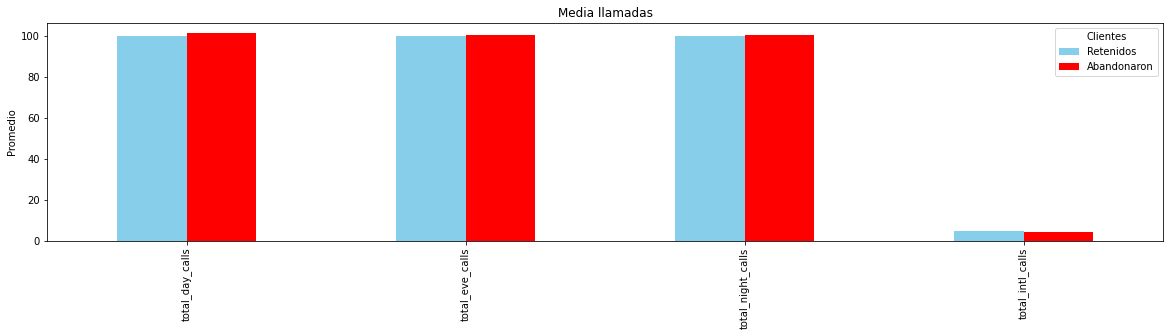

In [672]:
graficar_media(llamadas, "Media llamadas")

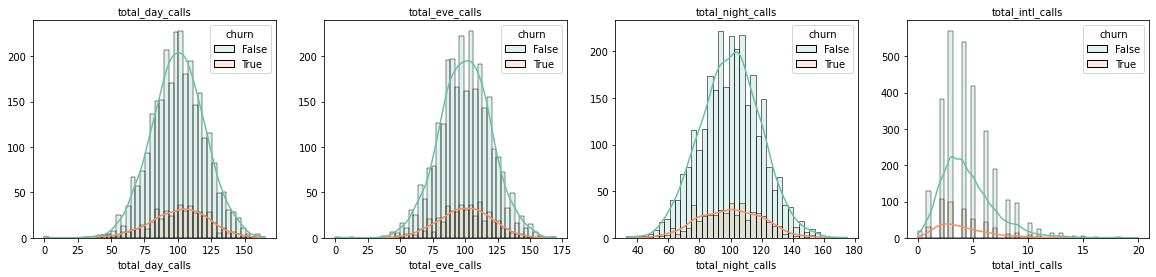

In [673]:
histogramas(llamadas)

total_calls
191    0.0
206    0.0
207    1.0
209    0.0
210    0.0
      ... 
398    1.0
399    0.0
403    0.0
408    1.0
416    0.0
Name: churn, Length: 195, dtype: float64


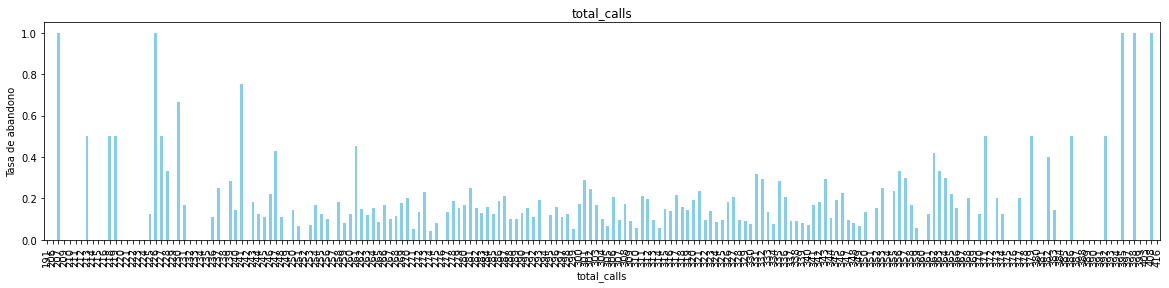

In [674]:
graf_tasa_churn('total_calls')

#### Cargos 

churn                   False      True 
total_day_charge    29.780421  35.175921
total_eve_charge    16.918909  18.054969
total_night_charge   9.006074   9.235528
total_intl_charge    2.743404   2.889545


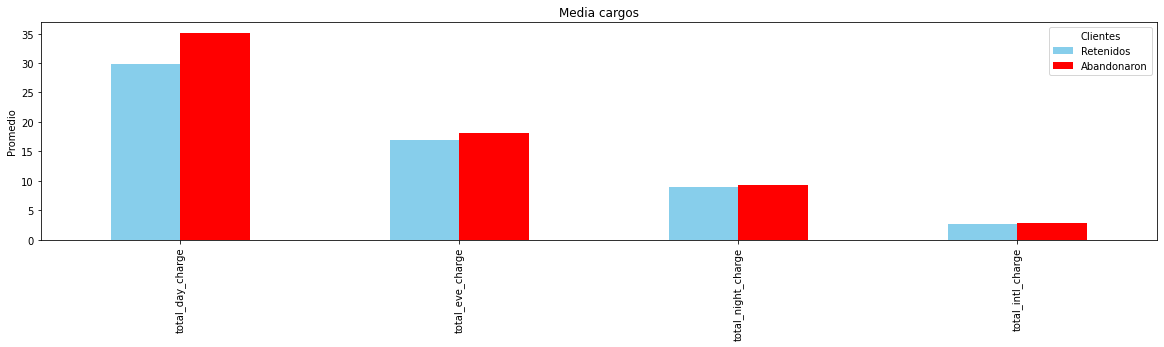

In [675]:
graficar_media(cargos, "Media cargos")

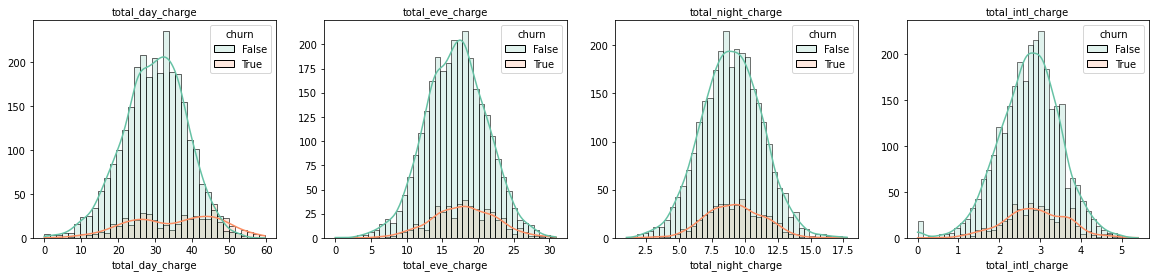

In [676]:
histogramas(cargos)

churn             False  True 
total_charge_>70              
False              2549    258
True                301    225


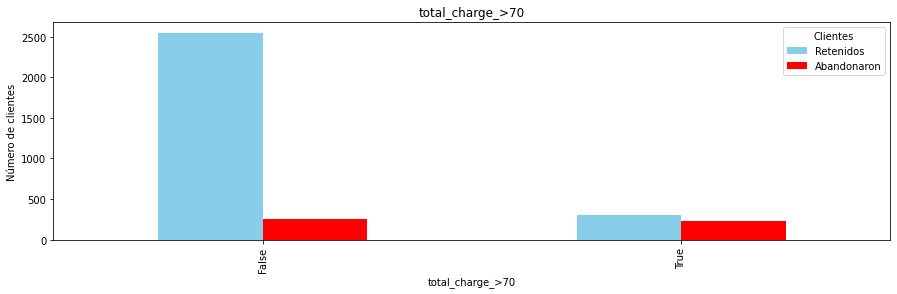

In [677]:
datos["total_charge_>70"] = datos["total_charge"]>70
graf_contingencia_churn("total_charge_>70")

total_charge_>70
False    0.091913
True     0.427757
Name: churn, dtype: float64


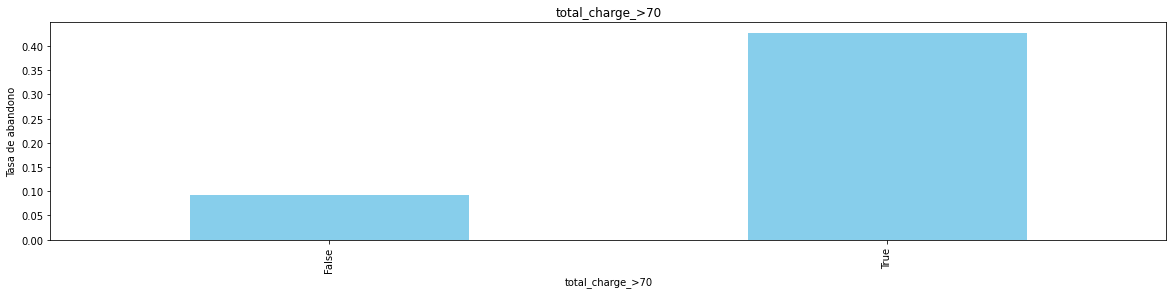

In [678]:
graf_tasa_churn("total_charge_>70")

#### Minutos

churn                     False       True 
total_day_minutes    175.175754  206.914079
total_eve_minutes    199.043298  212.410145
total_night_minutes  200.133193  205.231677
total_intl_minutes    10.158877   10.700000


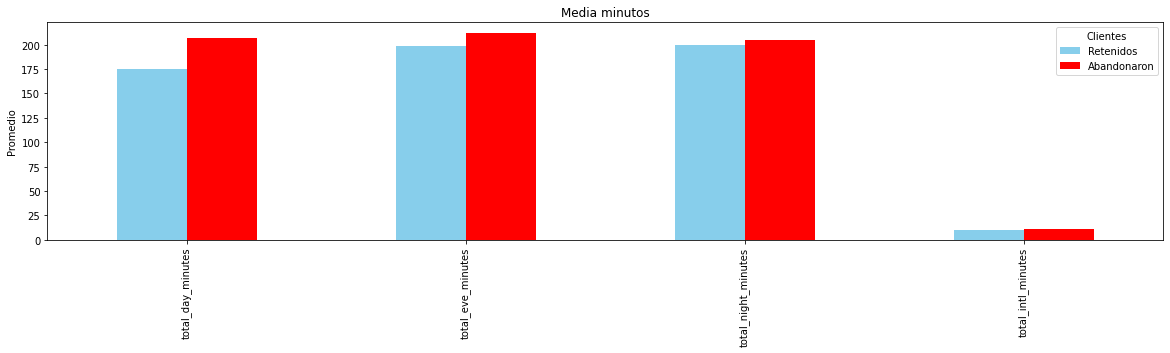

In [679]:
graficar_media(minutos, "Media minutos")

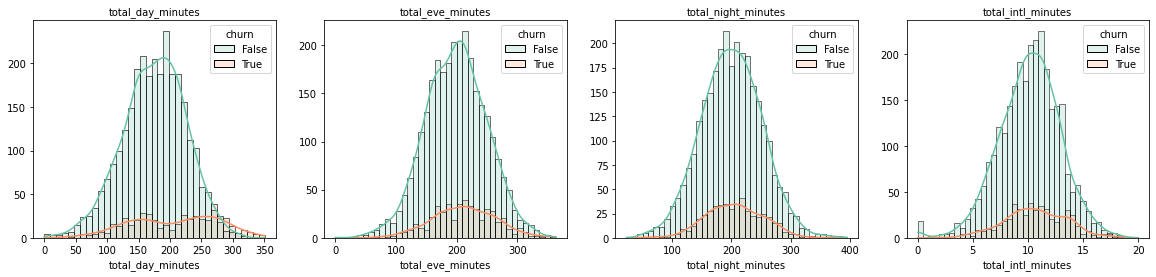

In [680]:
histogramas(minutos)

#### Duración cuenta y llamadas a servicio a cliente

churn                        False       True 
account_length          100.793684  102.664596
customer_service_calls    1.449825    2.229814


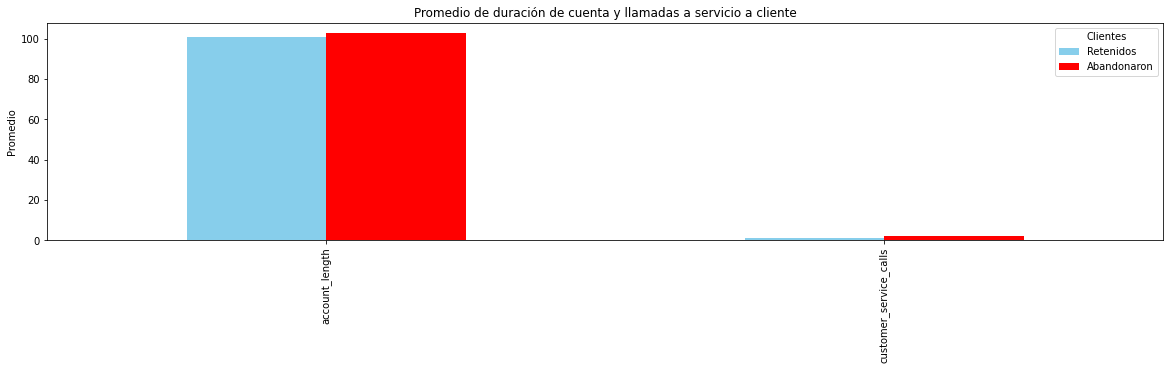

In [681]:
restantes = ["account_length", "customer_service_calls"]
graficar_media(restantes, "Promedio de duración de cuenta y llamadas a servicio a cliente")

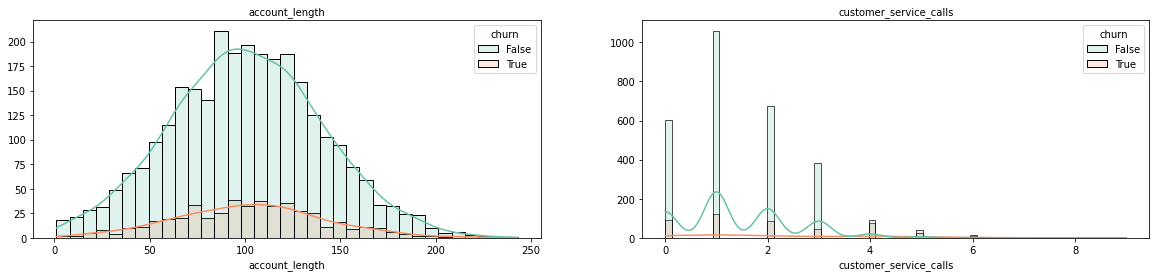

In [682]:
histogramas(restantes)

##### Llamadas a servicio

churn                   False  True 
customer_service_calls              
0                         605     92
1                        1059    122
2                         672     87
3                         385     44
4                          90     76
5                          26     40
6                           8     14
7                           4      5
8                           1      1
9                           0      2


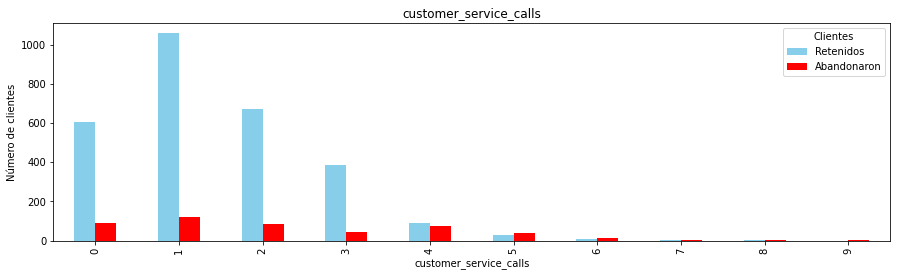

In [683]:
graf_contingencia_churn('customer_service_calls')

customer_service_calls
0    0.131994
1    0.103302
2    0.114625
3    0.102564
4    0.457831
5    0.606061
6    0.636364
7    0.555556
8    0.500000
9    1.000000
Name: churn, dtype: float64


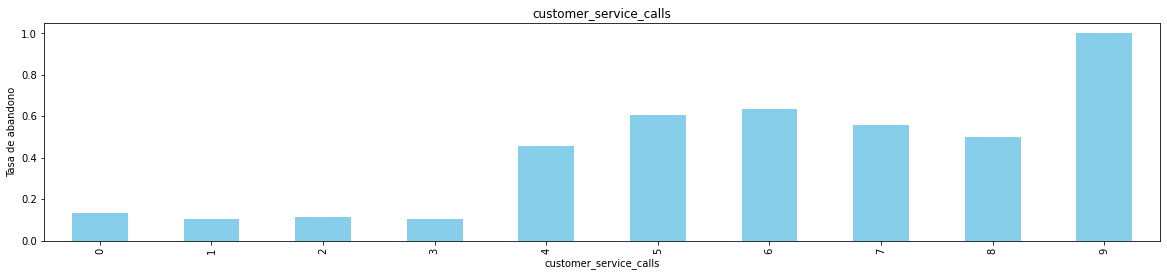

In [684]:
graf_tasa_churn('customer_service_calls')

churn                      False  True 
customer_service_calls_>4              
False                       2721    345
True                         129    138


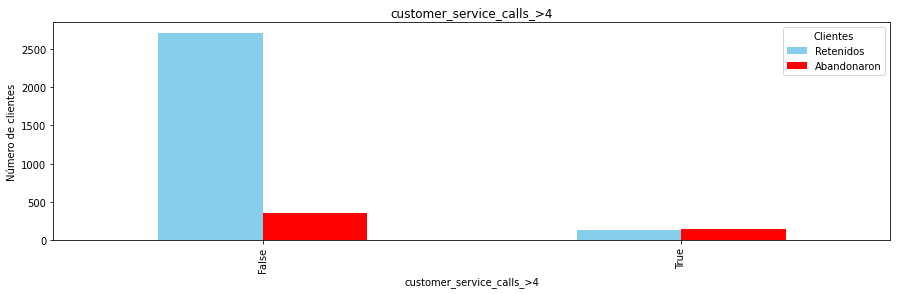

In [685]:
datos['customer_service_calls_>4'] = datos['customer_service_calls']>=4
graf_contingencia_churn('customer_service_calls_>4')

customer_service_calls_>4
False    0.112524
True     0.516854
Name: churn, dtype: float64


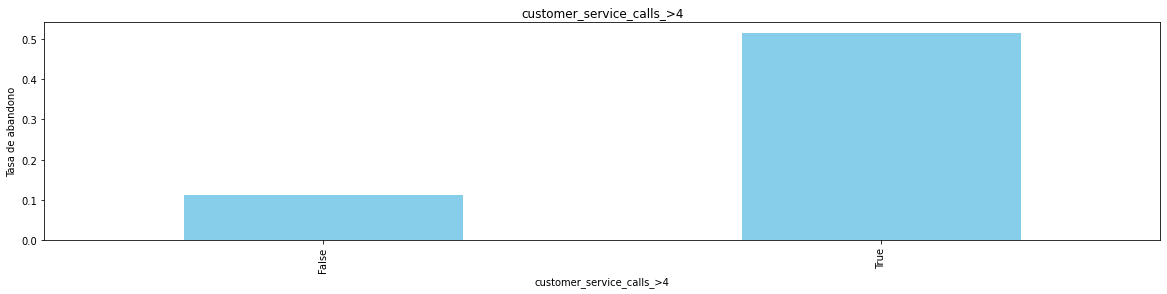

In [686]:
graf_tasa_churn('customer_service_calls_>4')

##### Duración de cuenta

churn           False  True 
account_length              
1                   7      1
2                   0      1
3                   5      0
4                   1      0
5                   1      0
...               ...    ...
221                 1      0
224                 1      1
225                 1      1
232                 1      0
243                 1      0

[212 rows x 2 columns]


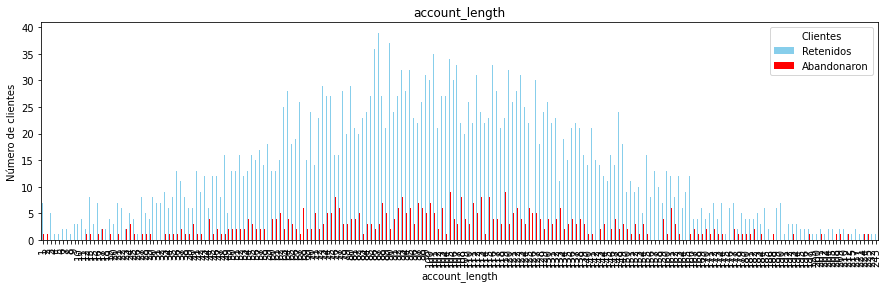

In [687]:
graf_contingencia_churn('account_length')

account_length
1      0.125
2      1.000
3      0.000
4      0.000
5      0.000
       ...  
221    0.000
224    0.500
225    0.500
232    0.000
243    0.000
Name: churn, Length: 212, dtype: float64


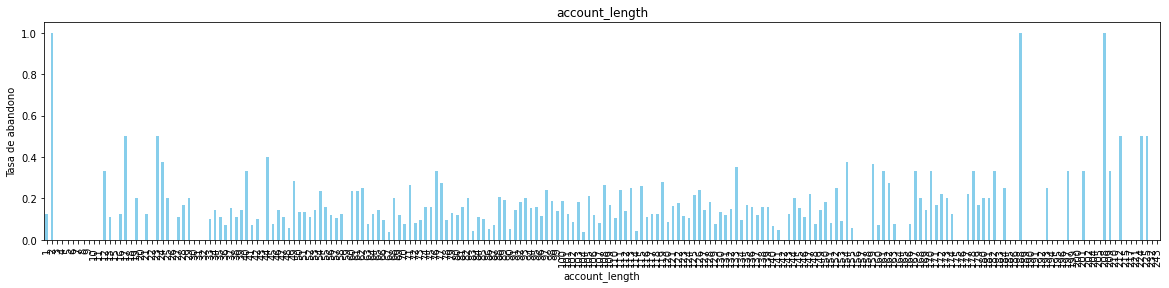

In [688]:
graf_tasa_churn('account_length')

#### Plan internacional

churn               False  True 
international_plan              
False                2664    346
True                  186    137


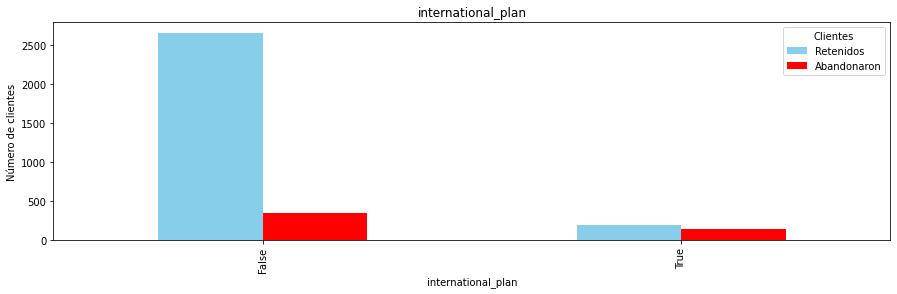

In [689]:
graf_contingencia_churn("international_plan")

international_plan
False    0.114950
True     0.424149
Name: churn, dtype: float64


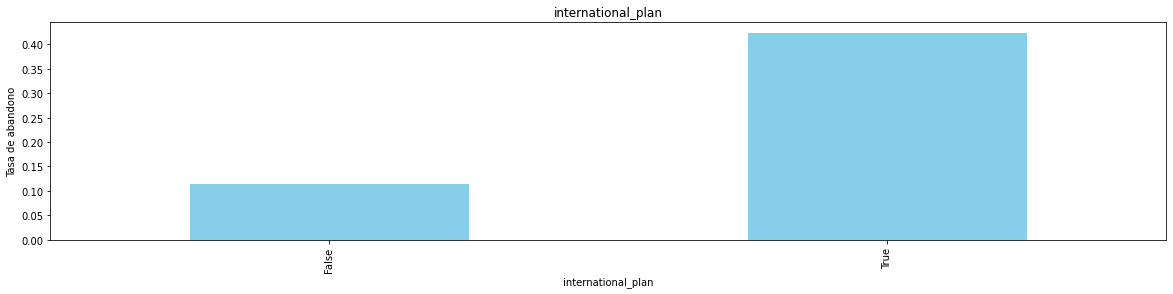

In [690]:
graf_tasa_churn("international_plan")

#### Buzón de voz

churn            False  True 
voice_mail_plan              
False             2008    403
True               842     80


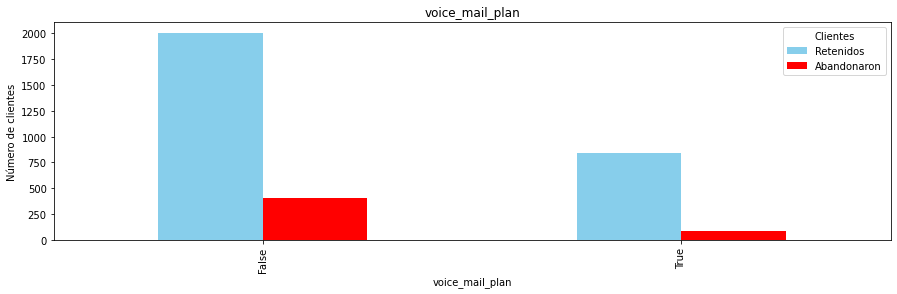

In [691]:
graf_contingencia_churn('voice_mail_plan')

voice_mail_plan
False    0.167151
True     0.086768
Name: churn, dtype: float64


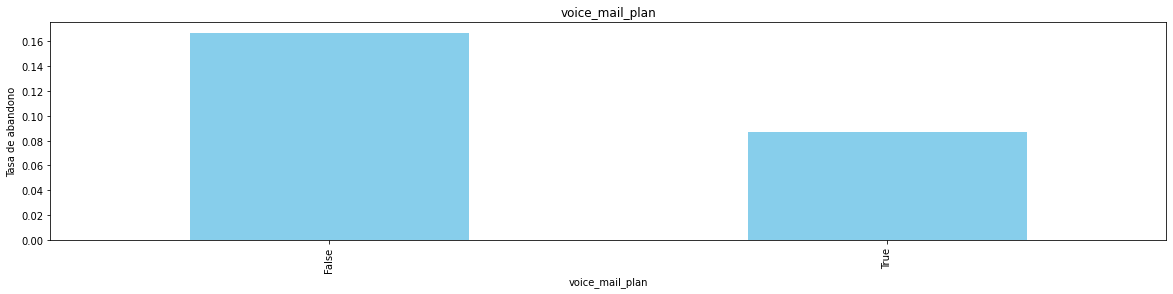

In [692]:
graf_tasa_churn('voice_mail_plan')

#### Código de área

churn      False  True 
area_code              
408          716    122
415         1419    236
510          715    125


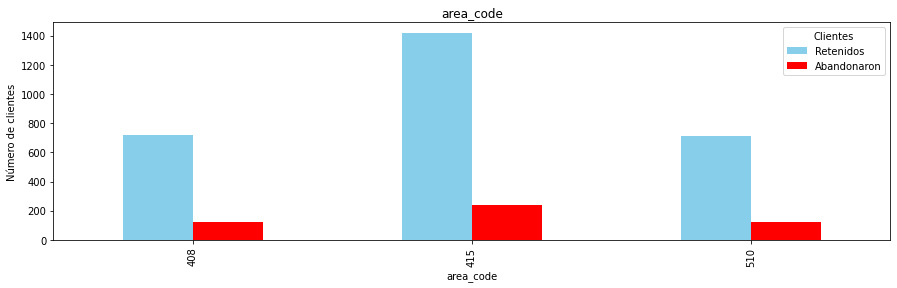

In [693]:
graf_contingencia_churn("area_code")

area_code
408    0.145585
415    0.142598
510    0.148810
Name: churn, dtype: float64


C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\1928732757.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tasa_churn = datos.groupby(col)["churn"].mean(True)#.sort_values(ascending=False)


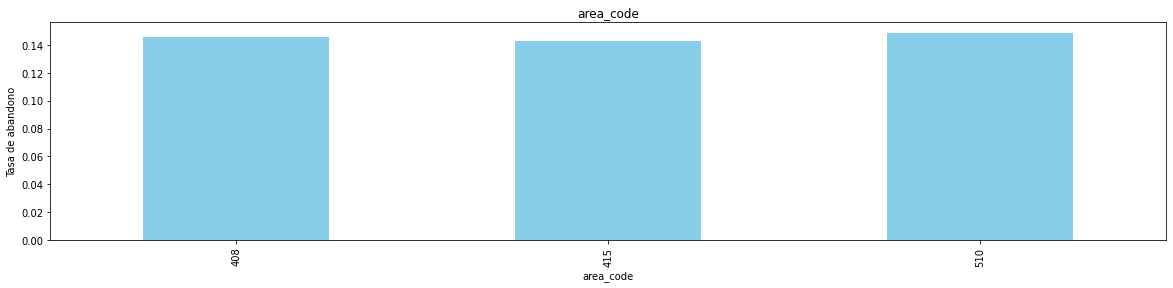

In [694]:
graf_tasa_churn("area_code")

#### Estados

churn  False  True 
state              
WV        96     10
VA        72      5
AL        72      8
WI        71      7
MN        69     15
NY        68     15
OH        68     10
WY        68      9
OR        67     11
VT        65      8
ID        64      9


<function matplotlib.pyplot.show(close=None, block=None)>

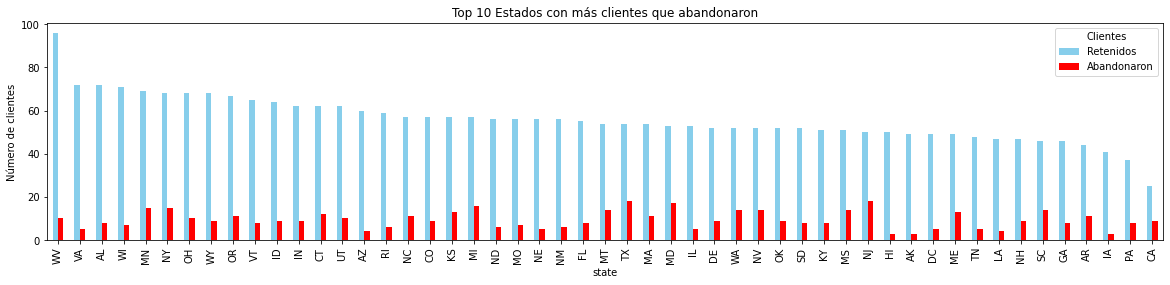

In [695]:
tabla_de_contingencia_estados = pd.crosstab(datos["state"], datos["churn"]).sort_values(by = False, ascending = False)
top10_estados = tabla_de_contingencia_estados.head(11)
print(top10_estados)

tabla_de_contingencia_estados.plot(kind='bar', color = {True: 'red', False: 'skyblue'}, figsize=(20,4))
plt.title('Top 10 Estados con más clientes que abandonaron')
plt.ylabel('Número de clientes')
plt.legend(labels=['Retenidos', 'Abandonaron'], title = 'Clientes')
plt.show

C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\3807189154.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tasa_churn_estados = datos.groupby("state")["churn"].mean(True).sort_values(ascending=False)


<function matplotlib.pyplot.show(close=None, block=None)>

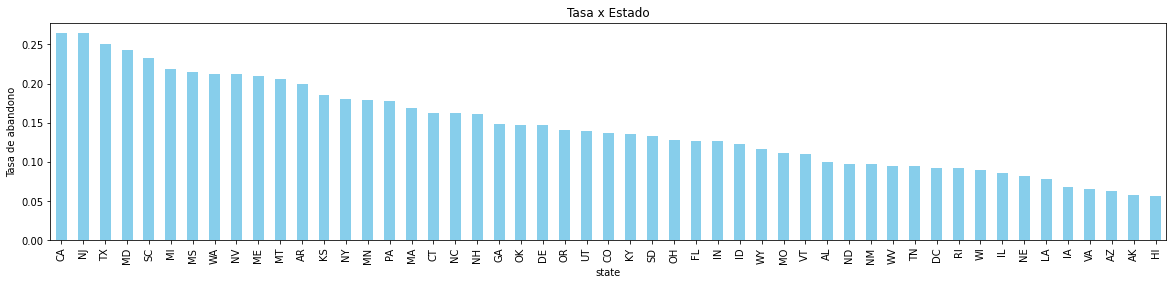

In [696]:
tasa_churn_estados = datos.groupby("state")["churn"].mean(True).sort_values(ascending=False)

tasa_churn_estados.plot(kind='bar', color = 'skyblue', figsize=(20,4))
plt.title('Tasa x Estado')
plt.ylabel('Tasa de abandono')
plt.show

##### Riesgo

In [697]:
q75 = tasa_churn_estados.quantile(0.75)
q25 = tasa_churn_estados.quantile(0.25)
estados_altos = tasa_churn_estados[tasa_churn_estados >= q75].index
estados_bajos = tasa_churn_estados[tasa_churn_estados <= q25].index
print(q75)
condiciones = [
    datos['state'].isin(estados_altos),
    datos['state'].isin(estados_bajos)
]
valores = ["High","Low"]
datos['state_risk'] =np.select(condiciones, valores, "Mid") 

0.1832185886402754


churn       False  True 
state_risk              
High          644    185
Low           751     65
Mid          1455    233


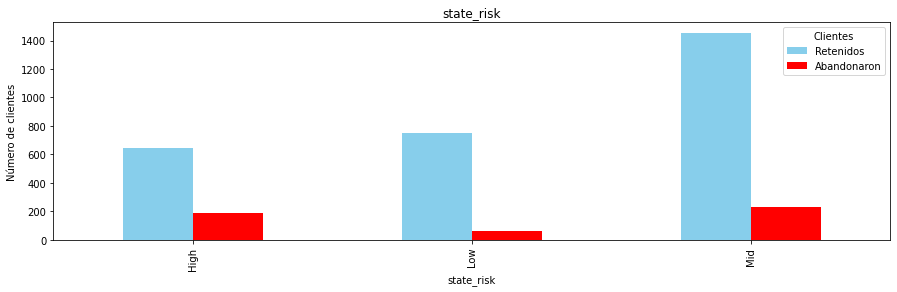

In [698]:
graf_contingencia_churn('state_risk')

state_risk
High    0.223160
Low     0.079657
Mid     0.138033
Name: churn, dtype: float64


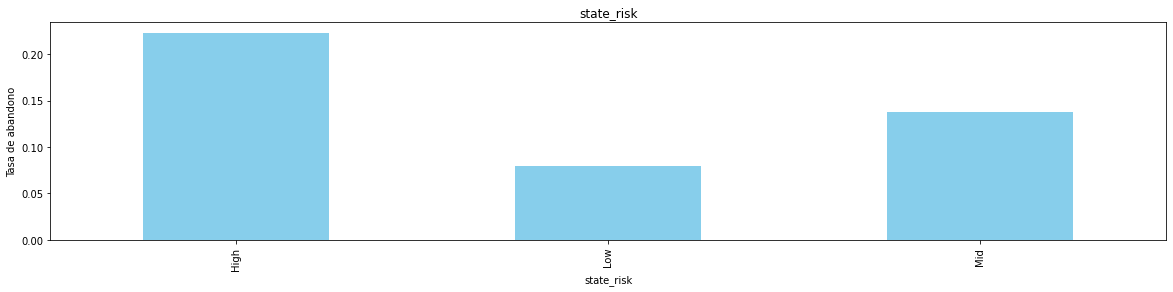

In [699]:
graf_tasa_churn('state_risk')

### Consultas estados

In [700]:
datos

,state,account_length,area_code,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,...,customer_service_calls,international_plan,voice_mail_plan,churn,total_calls,total_charge,total_minutes,total_charge_>70,customer_service_calls_>4,state_risk
id_customer,,,,,,,,,,,,,,,,,,,,,
1,LA,117,408,0,184.5,97,31.37,351.6,80,29.89,...,1,False,False,False,271,73.32,760.6,True,False,Low
2,IN,65,415,0,129.1,137,21.95,228.5,83,19.42,...,4,False,False,True,337,54.20,579.1,False,True,Mid
3,NY,161,415,0,332.9,67,56.59,317.8,97,27.01,...,4,False,False,True,301,92.29,816.7,True,True,Mid
4,SC,111,415,0,110.4,103,18.77,137.3,102,11.67,...,2,False,False,False,316,41.05,445.0,False,False,High
5,HI,49,510,0,119.3,117,20.28,215.1,109,18.28,...,1,False,False,False,317,49.60,524.2,False,False,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3329,SC,79,415,0,134.7,98,22.90,189.7,68,16.12,...,2,False,False,False,299,52.17,557.6,False,False,High
3330,AZ,192,415,36,156.2,77,26.55,215.5,126,18.32,...,2,False,True,False,292,60.10,660.7,False,False,Low
3331,WV,68,415,0,231.1,57,39.29,153.4,55,13.04,...,3,False,False,False,239,63.53,585.4,False,False,Low


In [701]:
columnas_interes = ['total_charge_>70', 'customer_service_calls_>4']
datos_agregados = datos.groupby(['state'])[columnas_interes].mean()
datos_estados = datos_estados.join(datos_agregados, how='inner')
datos_estados.info()

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 51 entries, CA to HI
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   churn                      51 non-null     float64
 1   account_length             51 non-null     float64
 2   customer_service_calls     51 non-null     float64
 3   total_day_minutes          51 non-null     float64
 4   total_eve_minutes          51 non-null     float64
 5   total_night_minutes        51 non-null     float64
 6   total_intl_minutes         51 non-null     float64
 7   total_minutes              51 non-null     float64
 8   total_day_charge           51 non-null     float64
 9   total_eve_charge           51 non-null     float64
 10  total_night_charge         51 non-null     float64
 11  total_intl_charge          51 non-null     float64
 12  total_charge               51 non-null     float64
 13  total_day_calls            51 non-null     fl

C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\3874769587.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  datos_agregados = datos.groupby(['state'])[columnas_interes].mean()


#### Funciones

In [702]:
def graf_promedios_churn_riesgo_estados(col):
    columnas = list(col)
    columnas.append('churn')

    df_estados = datos_estados[columnas].sort_values(by='churn', ascending = False)

    n_plots = len(columnas)
    fig, axes = plt.subplots(nrows=n_plots, ncols=1, figsize=(20, 4 * n_plots))
    axes = axes.flatten()
        
    for i, var in enumerate(df_estados):
        sns.barplot(data=df_estados, x=df_estados.index, y=var, ax=axes[i], hue = df_estados.index, legend = False, order = df_estados.index)
                
        axes[i].set_title(var, fontsize=10)
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

#### Llamadas

['total_day_calls', 'total_eve_calls', 'total_night_calls', 'total_intl_calls', 'total_calls']


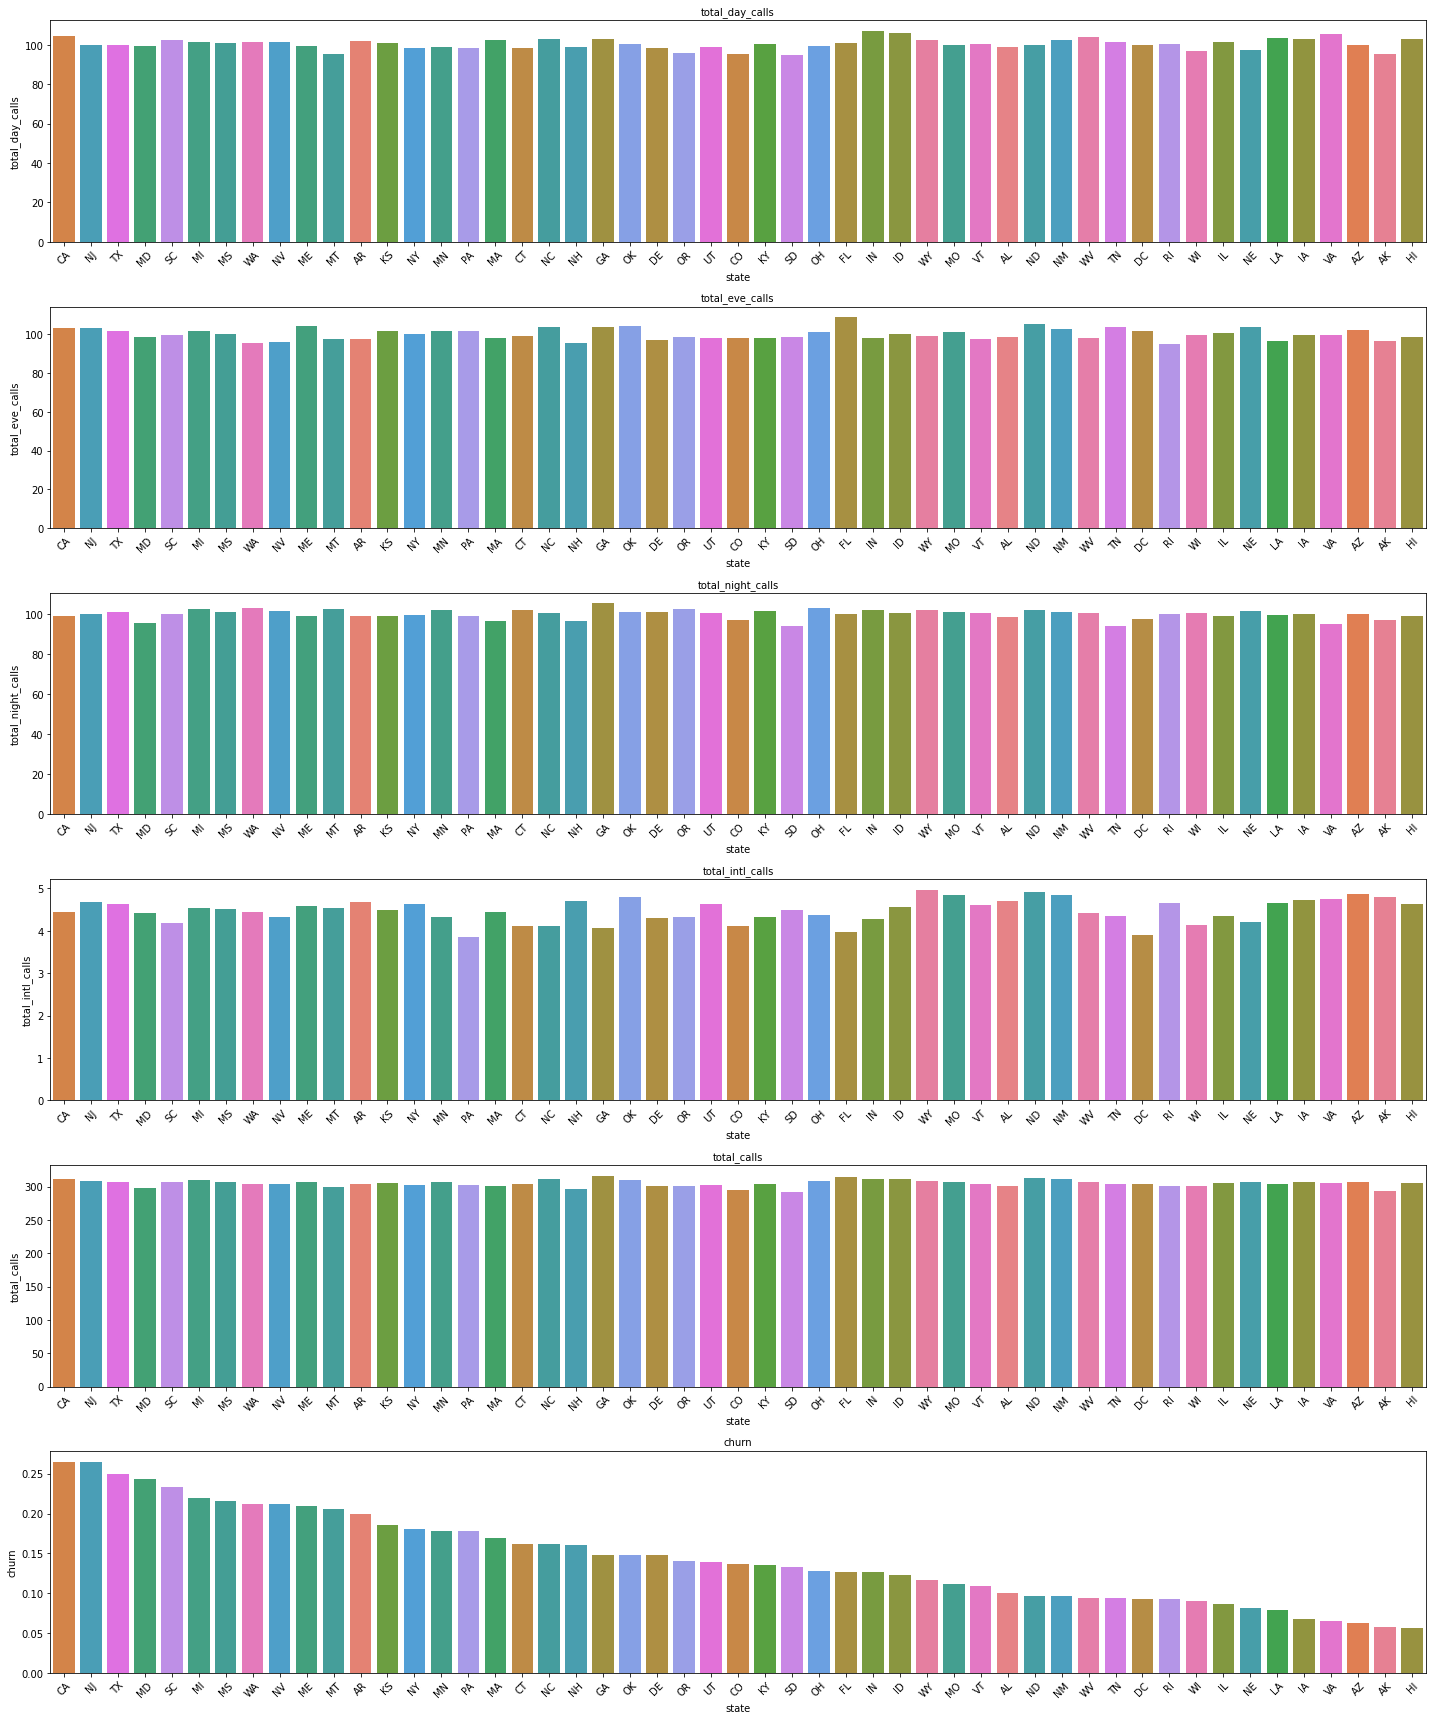

In [703]:
llamadas.append('total_calls')
print(llamadas)
graf_promedios_churn_riesgo_estados(llamadas)

#### Cargos

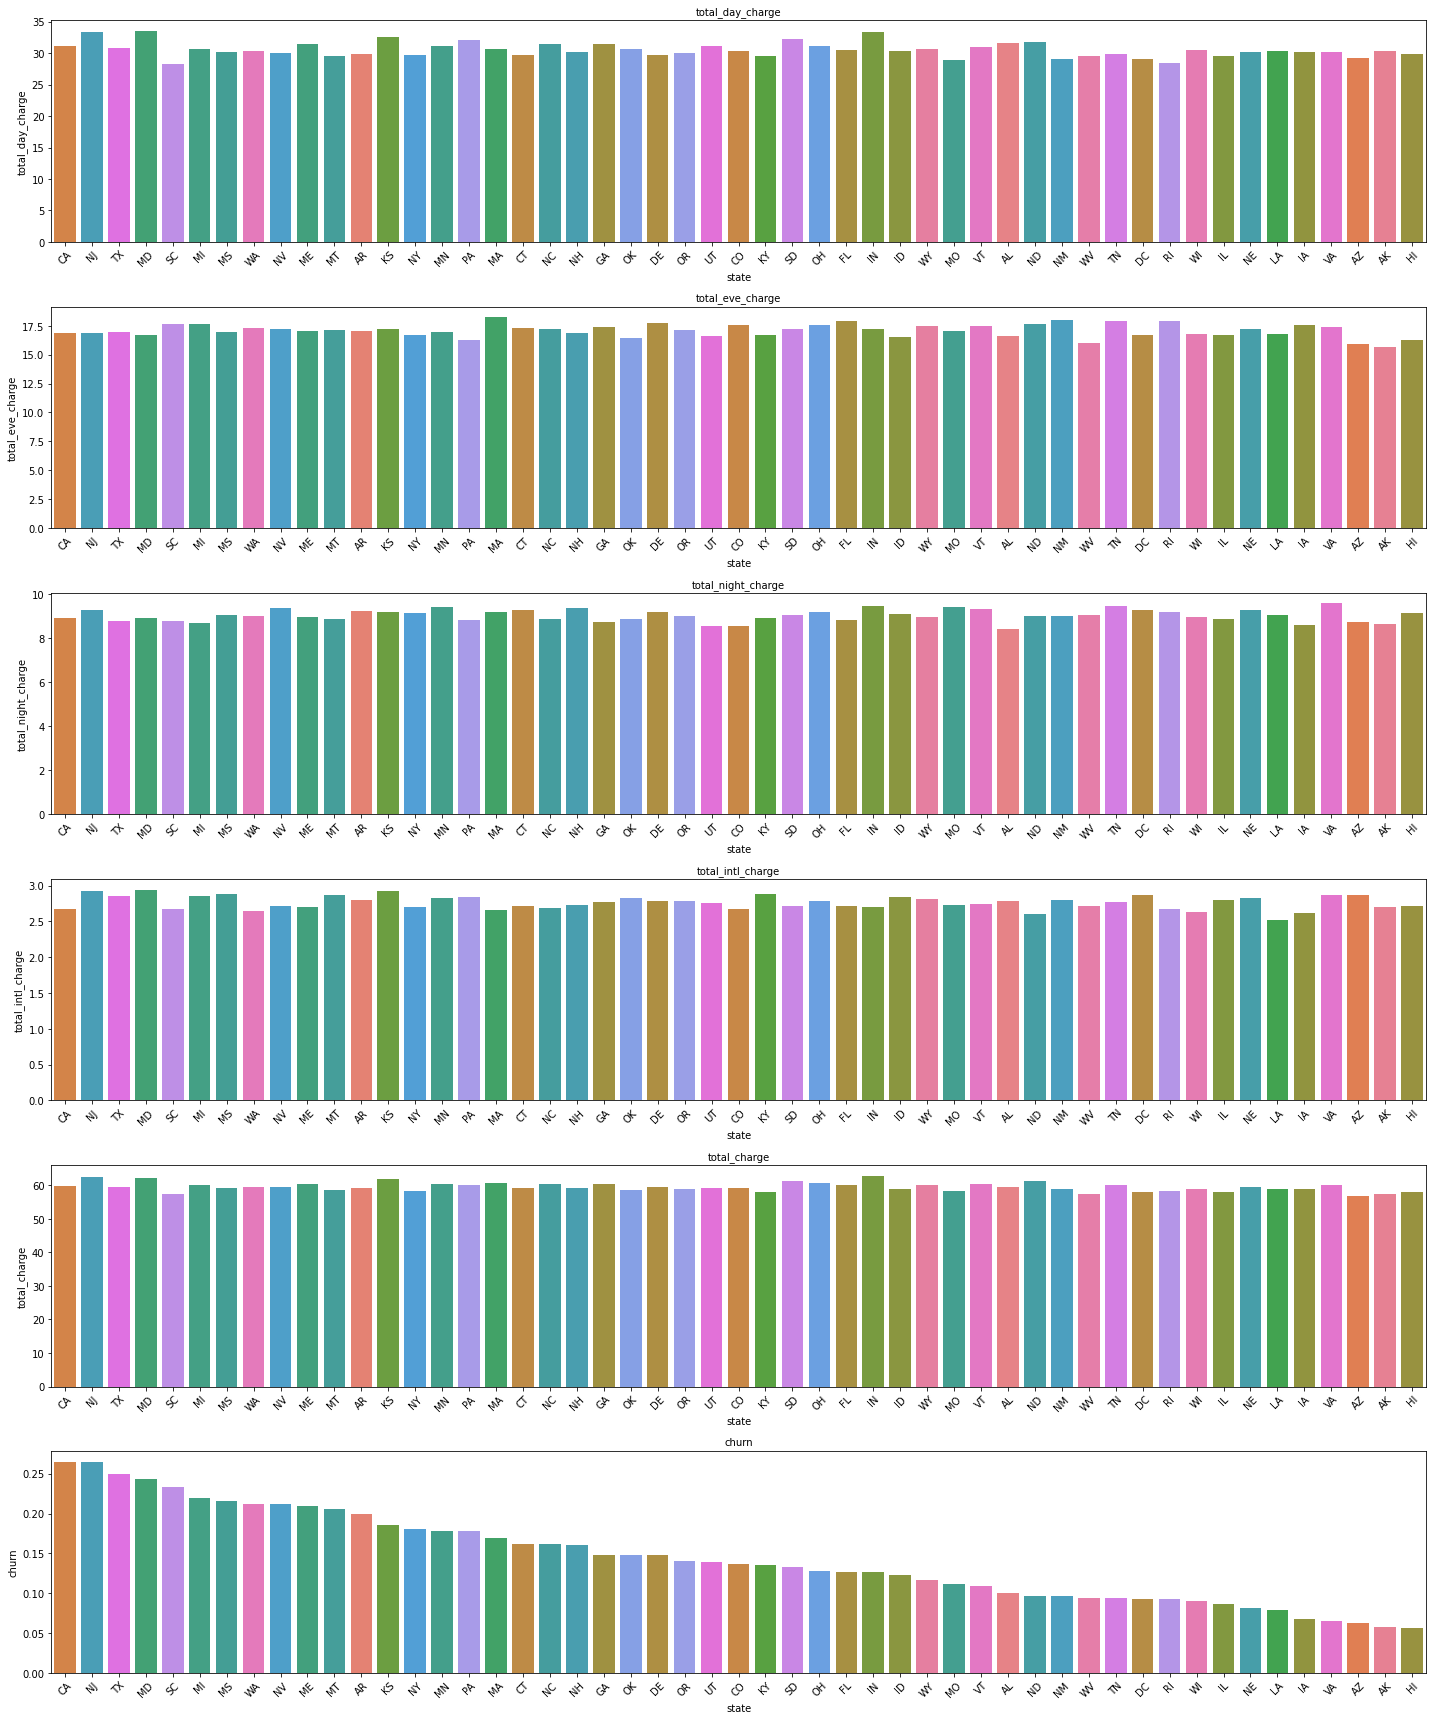

In [704]:
cargos.append('total_charge')
graf_promedios_churn_riesgo_estados(cargos)

#### Minutos

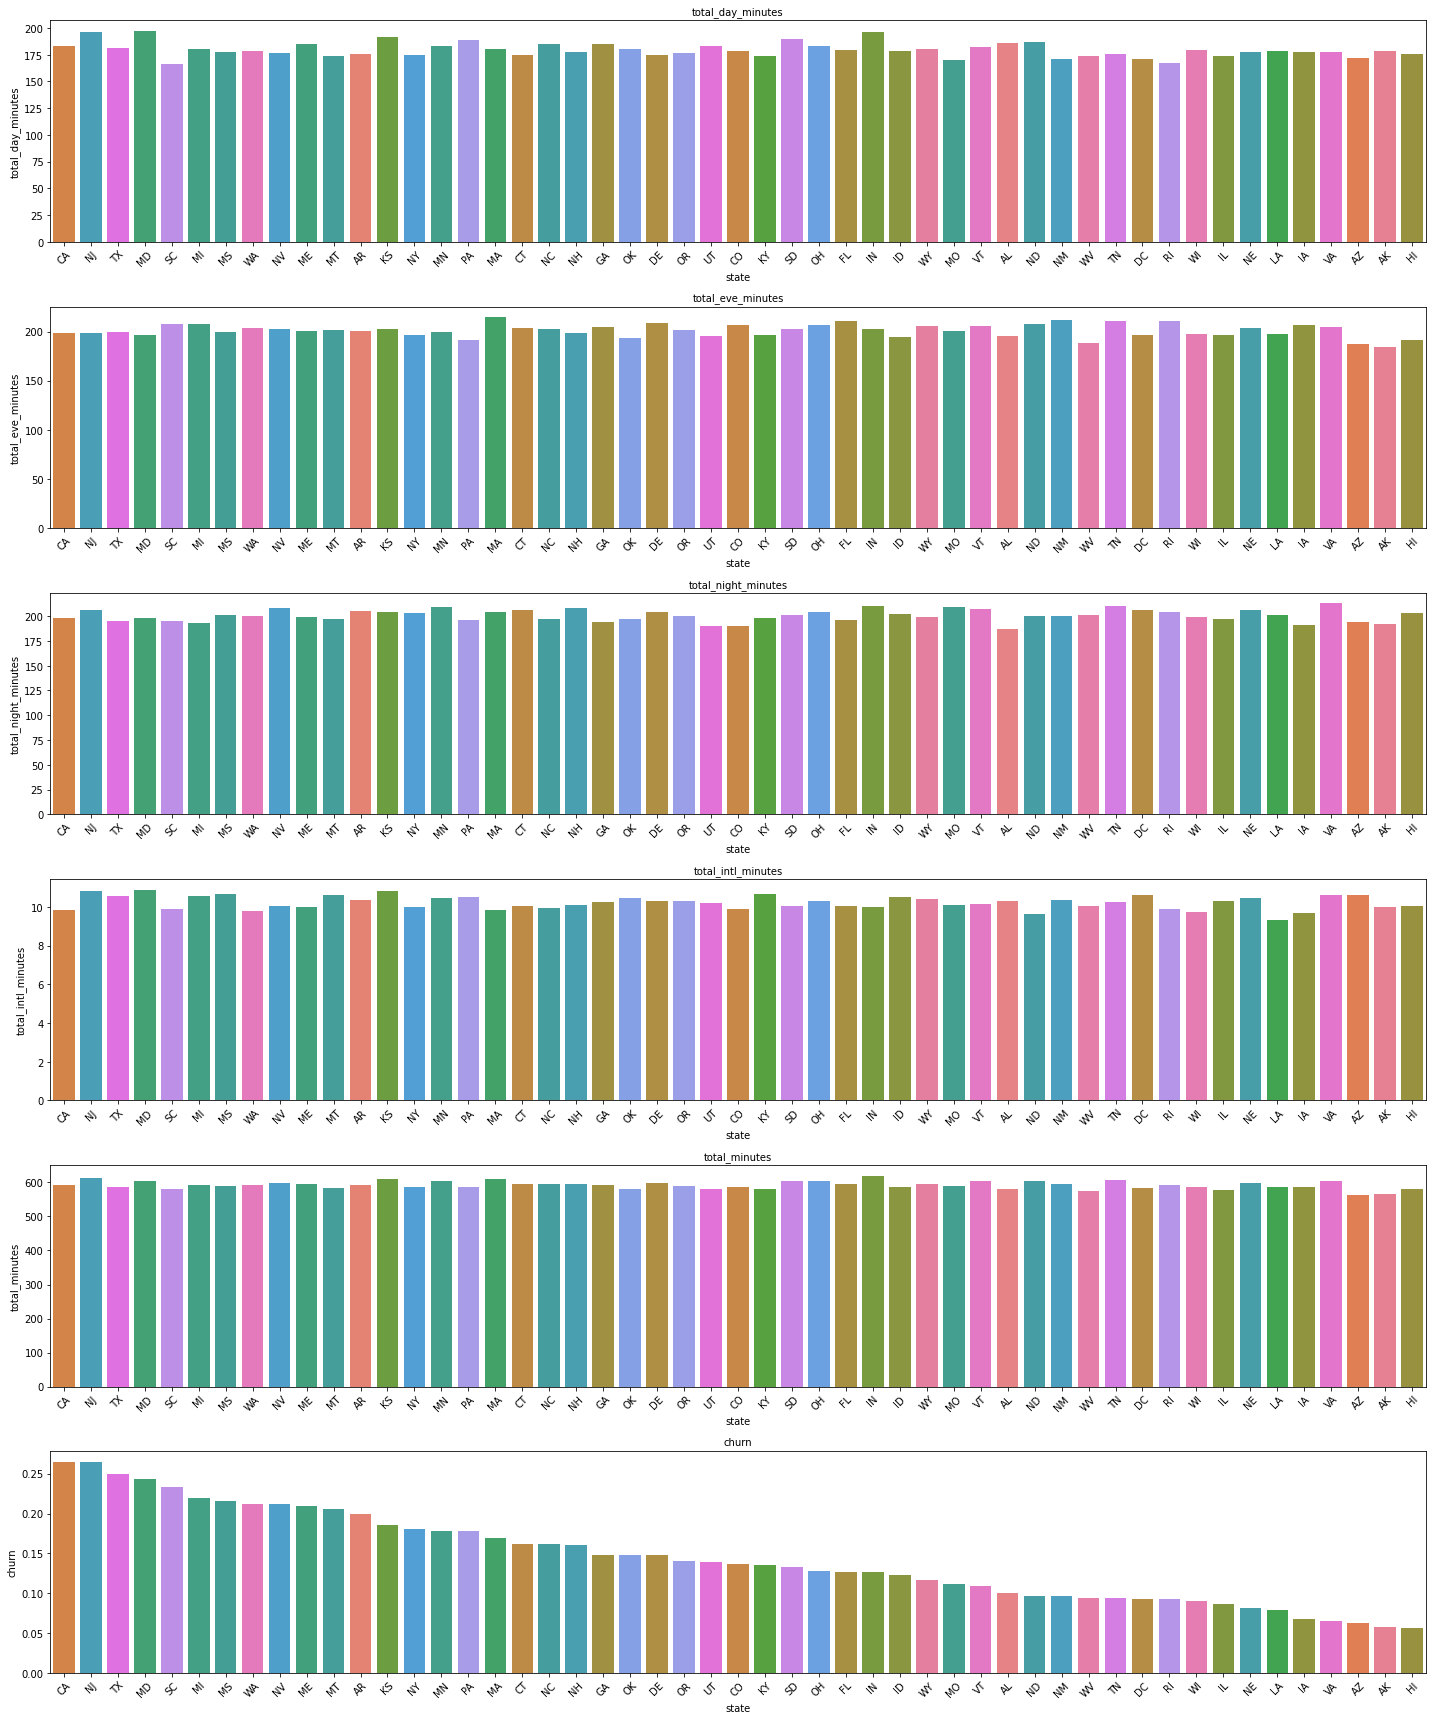

In [705]:
minutos.append('total_minutes')
graf_promedios_churn_riesgo_estados(minutos)

#### Duración de cuenta

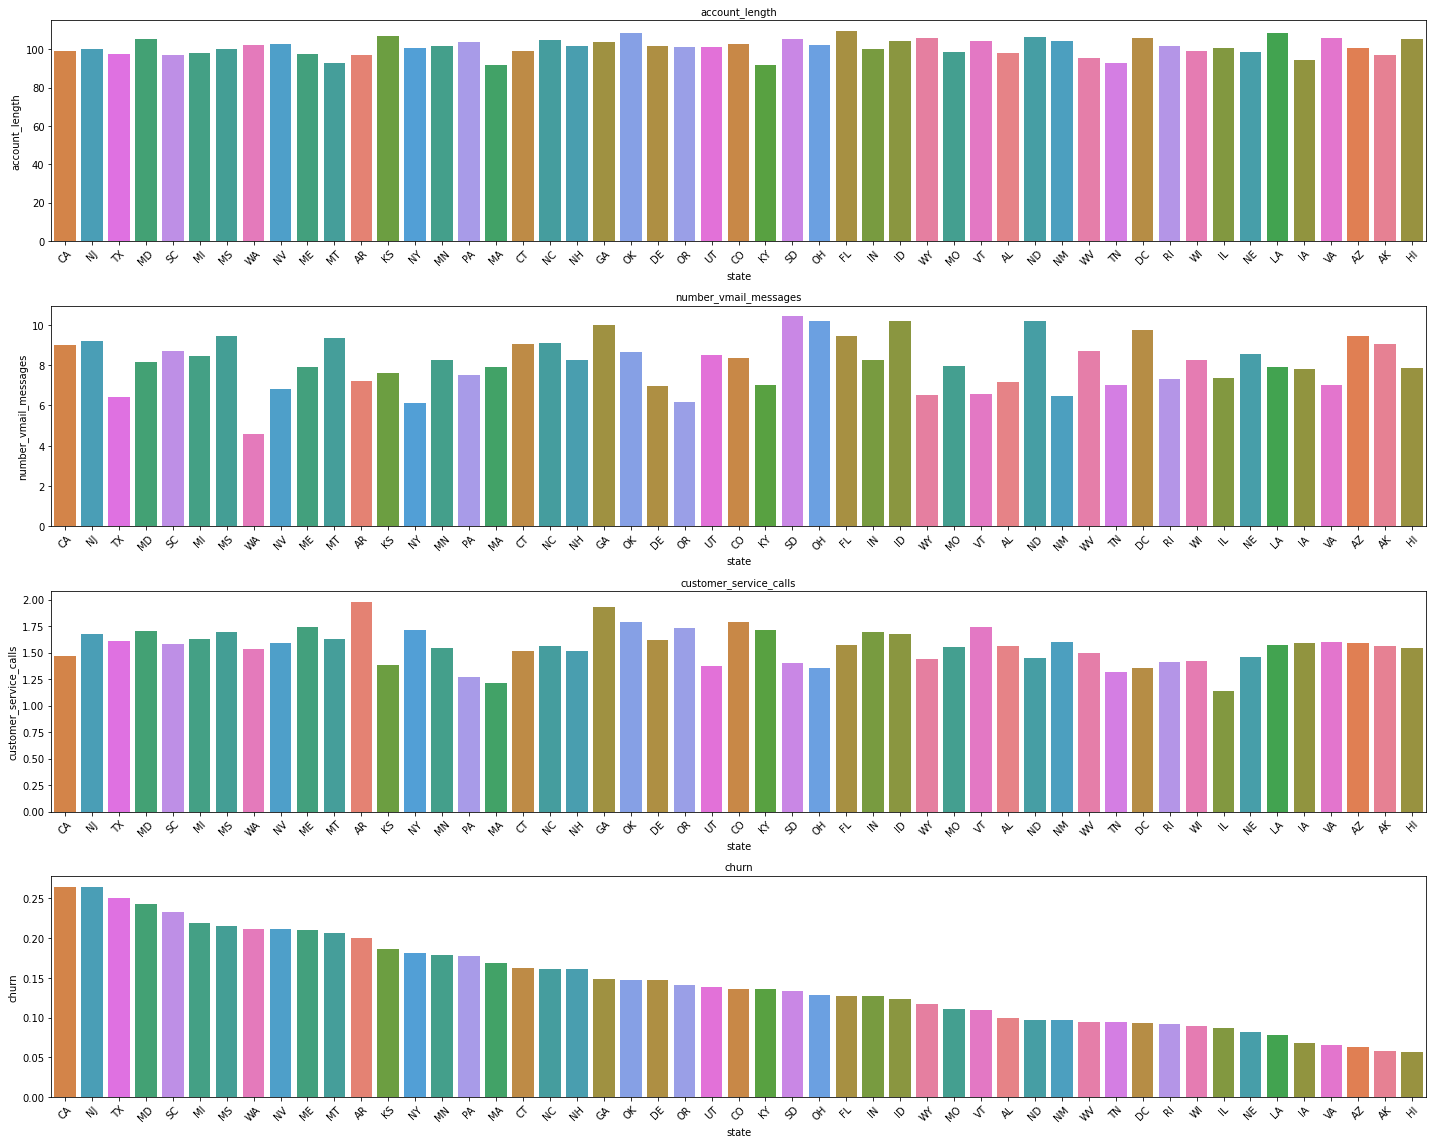

In [706]:
graf_promedios_churn_riesgo_estados(['account_length', 'number_vmail_messages', 'customer_service_calls'])

#### Planes

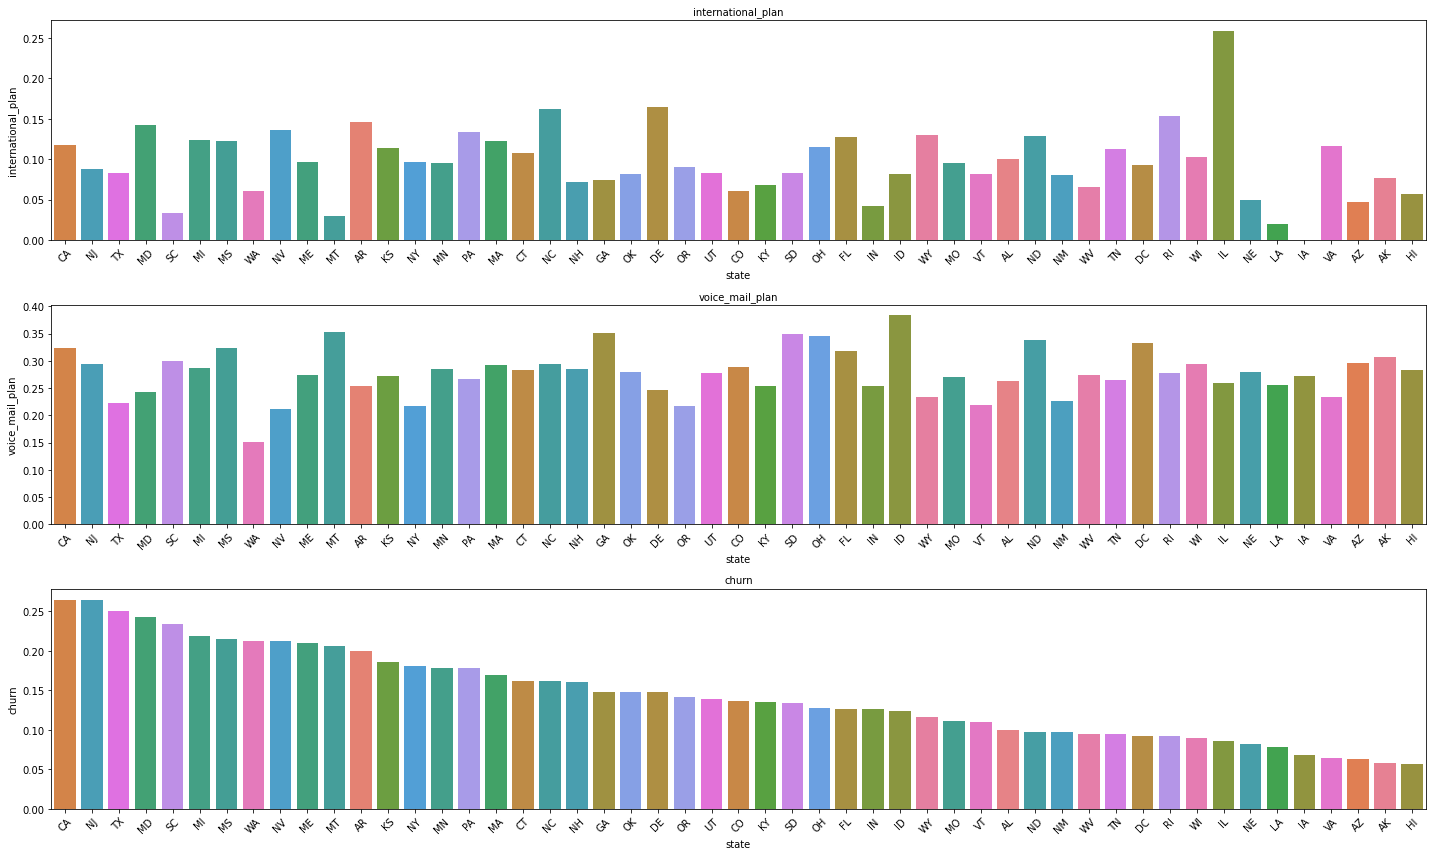

In [707]:
graf_promedios_churn_riesgo_estados(['international_plan', 'voice_mail_plan'])

#### Condicionales

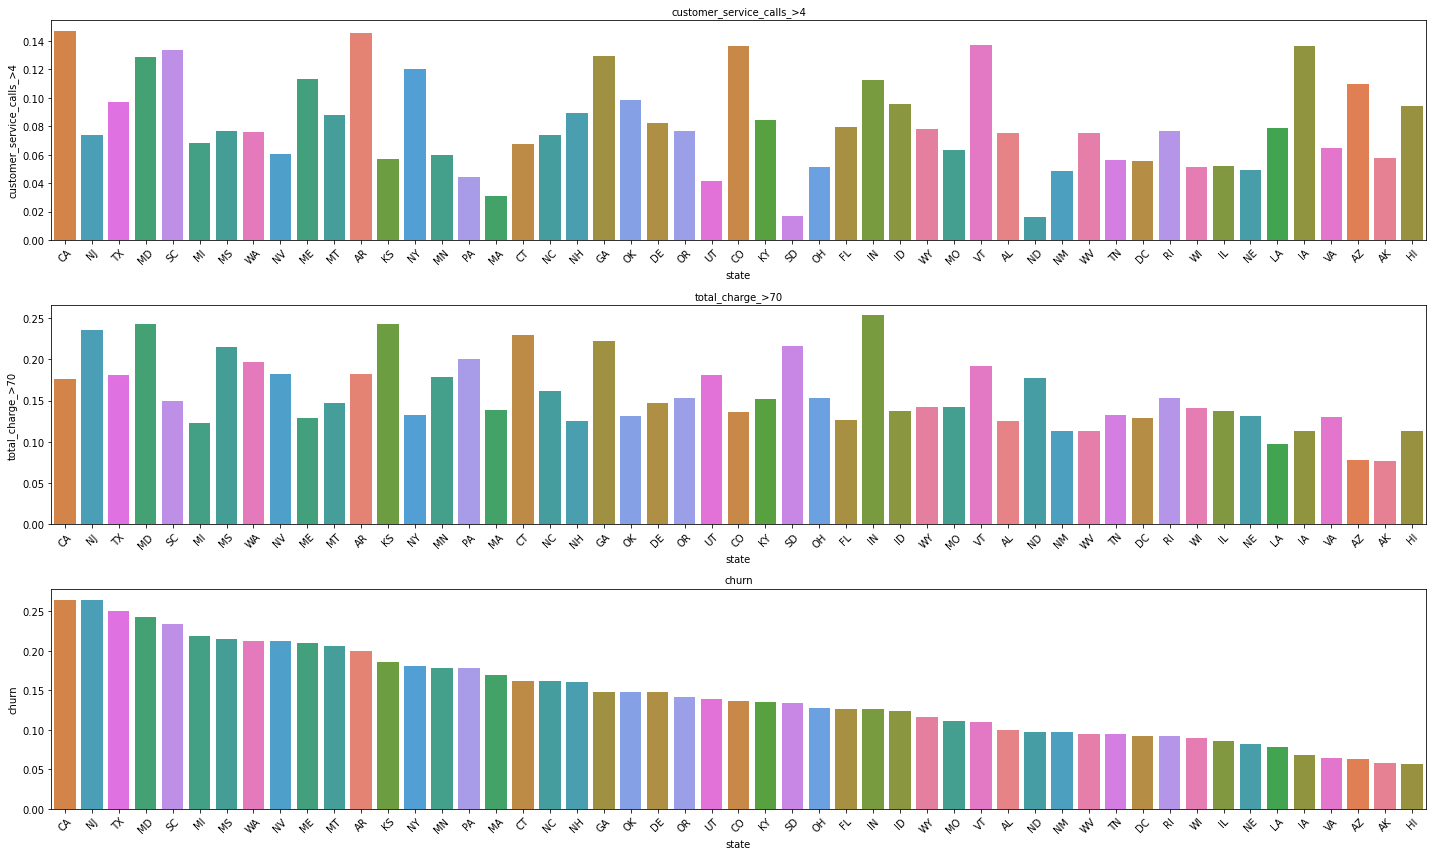

In [708]:
graf_promedios_churn_riesgo_estados(['customer_service_calls_>4', 'total_charge_>70'])

### Consultas riesgo

##### Funciones

In [709]:
def graf_promedios_churn_riesgo_estados(col, colname):
    """ Grafica comparativa de promedios de "riesgos" dividiendo x churn """
    df_promedios = datos.groupby(["state_risk","churn"])[col].mean()
    print(df_promedios)
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 4))

    for i, riesgo in enumerate(datos['state_risk'].unique()):
        df_estado = df_promedios.xs(key = riesgo, level='state_risk').reset_index()

        df_estado = pd.melt(df_estado, id_vars='churn', var_name='Tipo llamada', value_name='Promedio')

        sns.barplot(data=df_estado, x='Tipo llamada', y='Promedio', hue = 'churn',palette='Set2', ax=axes[i])
            
        axes[i].set_title(riesgo, fontsize=10)
        axes[i].set_ylabel(colname)
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

In [710]:
def top_tasa_churn_riesgos_estados(col):
    """ Grafica comparativa de tasa de churn """
    tasa_churn_estados = datos.groupby(["state_risk", col])["churn"].mean()
    proporciones = datos.groupby("state_risk")[col].mean().sort_values(ascending = False)

    individual_top_false = tasa_churn_estados.xs(False, level = col).nlargest(5)
    individual_top_true = tasa_churn_estados.xs(True, level = col).nlargest(5)
    estados_de_interes = individual_top_false.index.union(individual_top_true.index)
    # estados_de_interes = proporciones[estados_de_interes]

    fig, axis = plt.subplots(nrows = 1, ncols = 3, figsize = (20,4))

    proporciones.plot(kind = 'bar', color = 'orange', ax = axis[0], legend = False)
    axis[0].set_title(f"Proporciones de {col}")
    individual_top_false.plot(kind = 'bar', color = 'skyblue', ax = axis[1], legend = False)
    axis[1].set_title(f"Tasa {col} False")
    individual_top_true.plot(kind = 'bar', color = 'red', ax = axis[2], legend = False)
    axis[2].set_title(f"Tasa {col} True")
    plt.tight_layout()
    plt.show()

#### Llamadas

                  total_day_calls  total_eve_calls  total_night_calls  \
state_risk churn                                                        
High       False       100.062112        99.692547         100.368012   
           True        101.962162       101.594595         100.243243   
Low        False       100.672437        99.635153          99.091877   
           True        105.030769        99.938462          97.461538   
Mid        False       100.180069       100.400000         100.419931   
           True         99.806867        99.914163         101.343348   

                  total_intl_calls  total_calls  
state_risk churn                                 
High       False          4.604037   304.726708  
           True           4.172973   307.972973  
Low        False          4.536618   303.936085  
           True           3.861538   306.292308  
Mid        False          4.499656   305.499656  
           True           4.240343   305.304721  


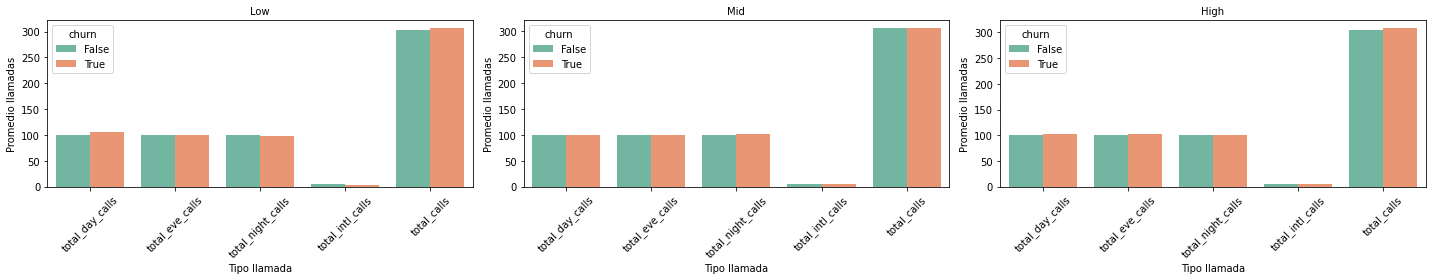

In [711]:
graf_promedios_churn_riesgo_estados(llamadas, 'Promedio llamadas')

#### Cargos

                  total_day_charge  total_eve_charge  total_night_charge  \
state_risk churn                                                           
High       False         29.723913         16.887981            8.931988   
           True          35.333784         18.041243            9.254324   
Low        False         29.424993         16.738735            9.066312   
           True          33.788000         17.517846            9.325077   
Mid        False         29.988887         17.025595            9.007773   
           True          35.437768         18.215708            9.195622   

                  total_intl_charge  total_charge  
state_risk churn                                   
High       False           2.777127     58.321009  
           True            2.938324     65.567676  
Low        False           2.727696     57.957736  
           True            2.875385     63.506308  
Mid        False           2.736584     58.758838  
           True            

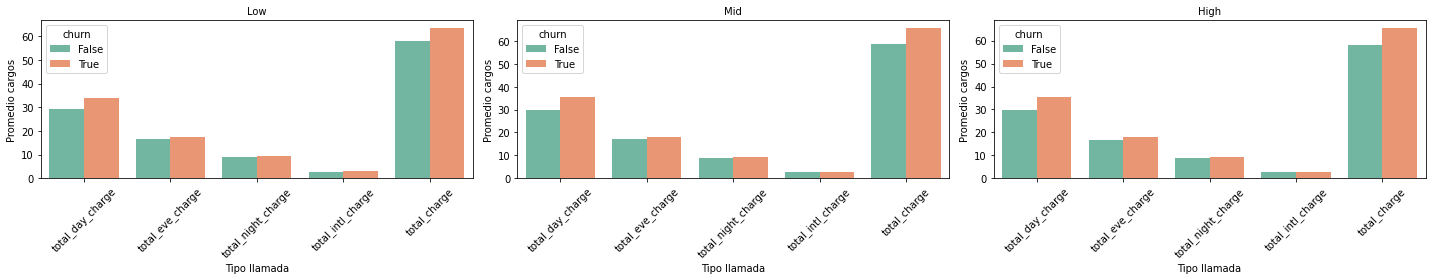

In [712]:
graf_promedios_churn_riesgo_estados(cargos, 'Promedio cargos')

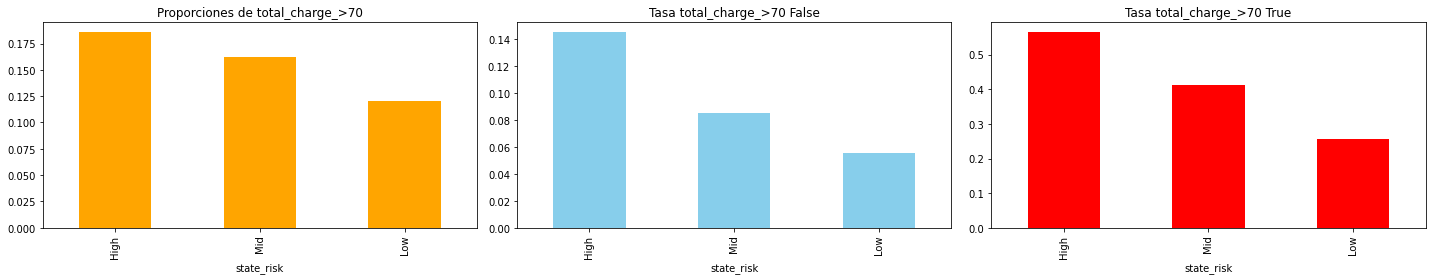

In [713]:
top_tasa_churn_riesgos_estados("total_charge_>70")

#### Minutos

                  total_day_minutes  total_eve_minutes  total_night_minutes  \
state_risk churn                                                              
High       False         174.843323         198.679503           198.490839   
           True          207.843243         212.247568           205.650270   
Low        False         173.085486         196.924501           201.469774   
           True          198.749231         206.087692           207.216923   
Mid        False         176.401787         200.297938           200.170241   
           True          208.454077         214.303004           204.345494   

                  total_intl_minutes  total_minutes  
state_risk churn                                     
High       False           10.283540     582.297205  
           True            10.881081     636.622162  
Low        False           10.100666     581.580426  
           True            10.647692     622.701538  
Mid        False           10.133746     58

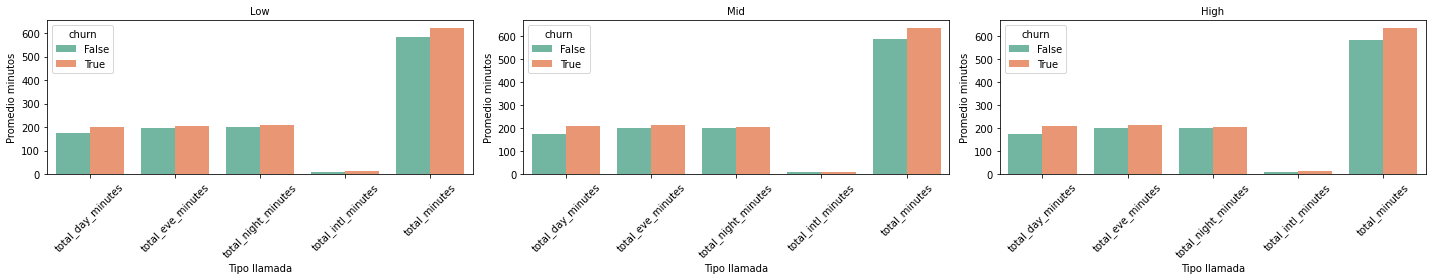

In [714]:
graf_promedios_churn_riesgo_estados(minutos, 'Promedio minutos')

#### Duración cuenta y llamadas a servicio a cliente

                  account_length  customer_service_calls
state_risk churn                                        
High       False       99.105590                1.468944
           True       102.259459                2.205405
Low        False      100.448735                1.404794
           True        98.338462                2.200000
Mid        False      101.718900                1.464605
           True       104.193133                2.257511


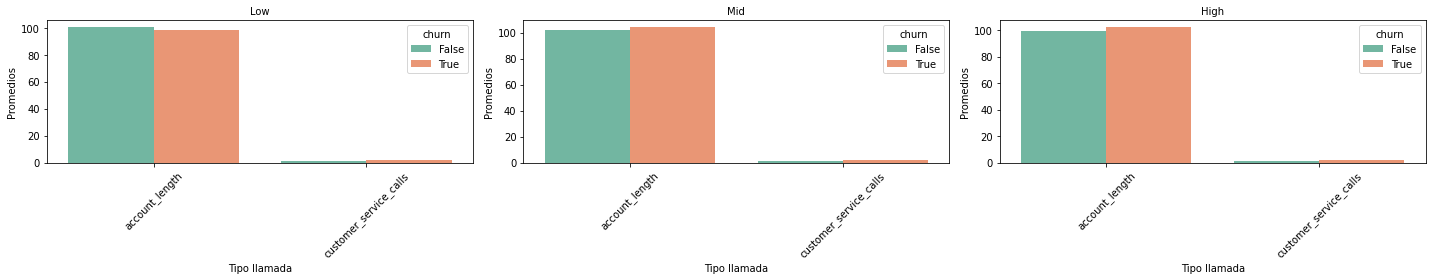

In [715]:
graf_promedios_churn_riesgo_estados(restantes, "Promedios")

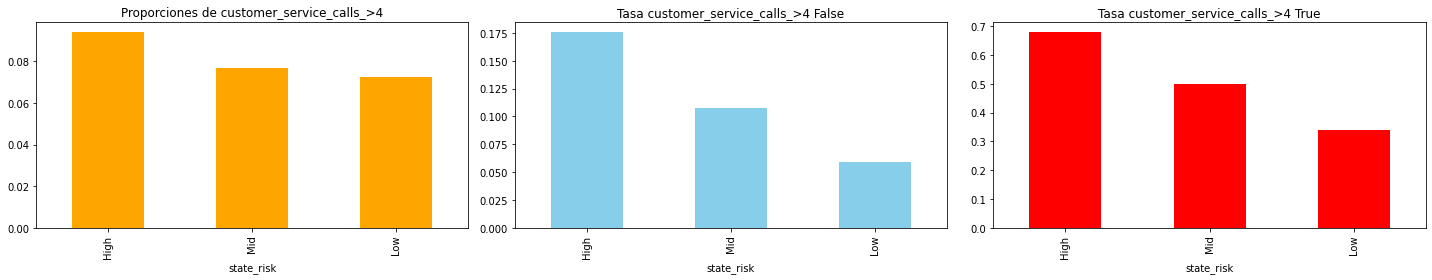

In [716]:
top_tasa_churn_riesgos_estados("customer_service_calls_>4")

#### Plan internacional

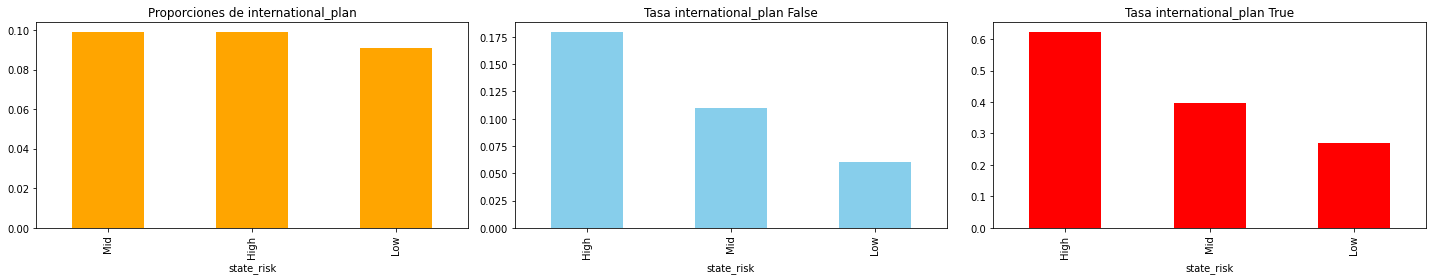

In [717]:
top_tasa_churn_riesgos_estados("international_plan")

#### Voice mail plan

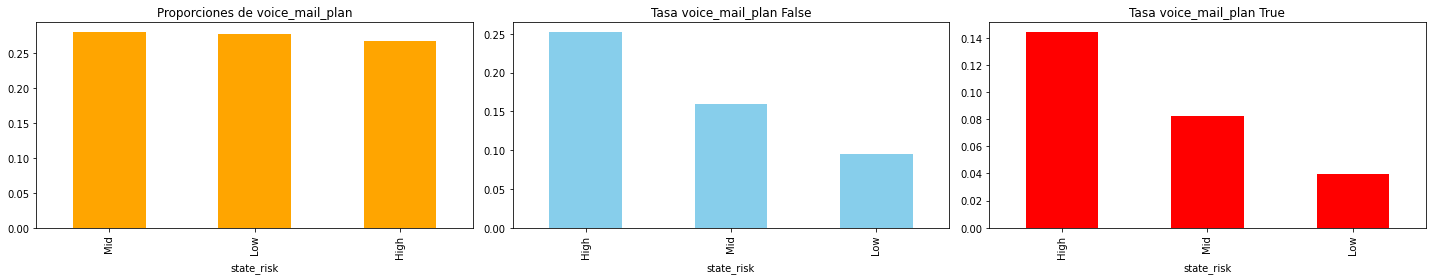

In [718]:
top_tasa_churn_riesgos_estados("voice_mail_plan")

## Correlaciones 

### Estados

In [722]:
datos_estados.info()

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 51 entries, CA to HI
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   churn                      51 non-null     float64
 1   account_length             51 non-null     float64
 2   customer_service_calls     51 non-null     float64
 3   total_day_minutes          51 non-null     float64
 4   total_eve_minutes          51 non-null     float64
 5   total_night_minutes        51 non-null     float64
 6   total_intl_minutes         51 non-null     float64
 7   total_minutes              51 non-null     float64
 8   total_day_charge           51 non-null     float64
 9   total_eve_charge           51 non-null     float64
 10  total_night_charge         51 non-null     float64
 11  total_intl_charge          51 non-null     float64
 12  total_charge               51 non-null     float64
 13  total_day_calls            51 non-null     fl

In [723]:
corr_estados = datos_estados.corr()
corr_estados['churn']

churn                        1.000000
account_length              -0.145175
customer_service_calls       0.255309
total_day_minutes            0.333836
total_eve_minutes            0.118873
total_night_minutes         -0.036539
total_intl_minutes           0.257300
total_minutes                0.256704
total_day_charge             0.333854
total_eve_charge             0.118927
total_night_charge          -0.036743
total_intl_charge            0.257558
total_charge                 0.359307
total_day_calls             -0.038586
total_eve_calls              0.065268
total_night_calls            0.129959
total_intl_calls            -0.148464
total_calls                  0.068246
international_plan           0.132656
voice_mail_plan             -0.069493
number_vmail_messages       -0.057821
total_charge_>70             0.560529
customer_service_calls_>4    0.279573
Name: churn, dtype: float64

<Axes: >

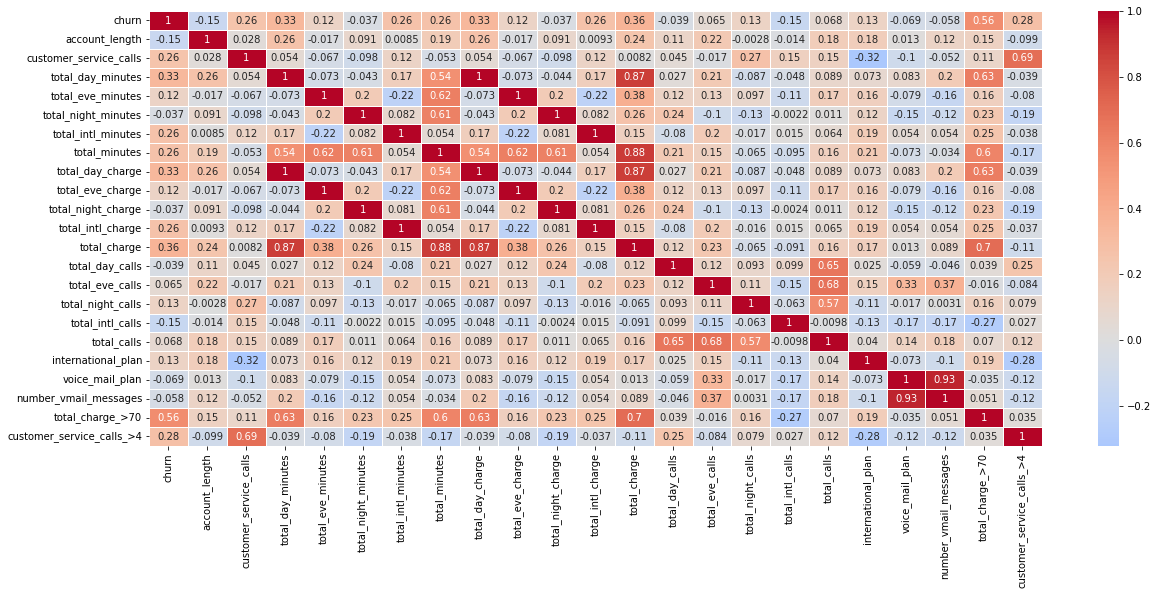

In [724]:
plt.figure(figsize = (20,8))
sns.heatmap(corr_estados, cmap = "coolwarm", annot=True, center=0, linewidths=0.5)

#### Scatterplots

##### Funciones

In [725]:
def scatterplots(datos_, principal, columnas):
    """Histograma coloreando x churn"""
    n_columnas = len(columnas)
    fig, axes = plt.subplots(nrows=math.ceil(n_columnas/2), ncols=2, figsize = (20,3*n_columnas))
    axes = axes.flatten()

    for i,col in enumerate(columnas):
        sns.scatterplot(data=datos_, x=principal, y = col, color = 'crimson', s=100, ax=axes[i])
        axes[i].set_title(col, fontsize = 10)
        axes[i].set_ylabel('')
    plt.tight_layout
    plt.show

##### Llamadas

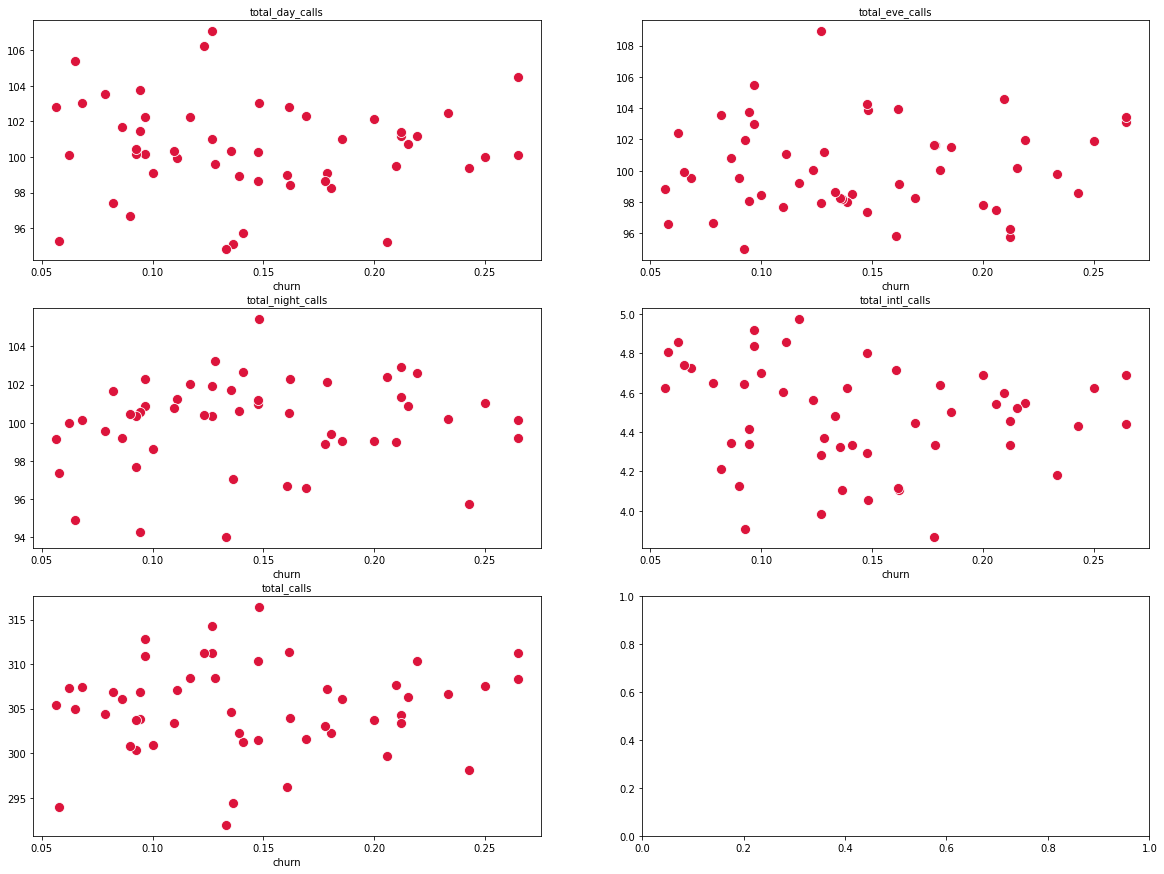

In [726]:
scatterplots(datos_estados, 'churn', llamadas)

##### Cargos

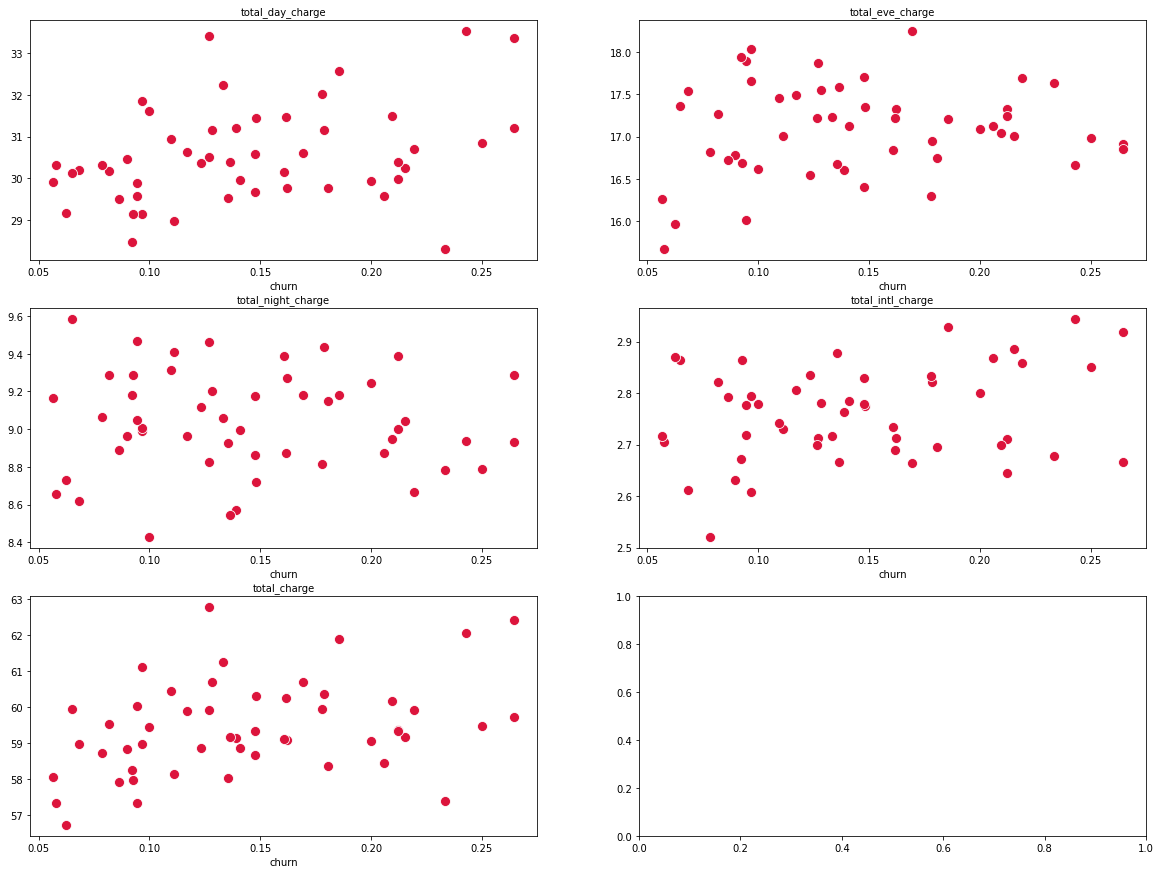

In [727]:
scatterplots(datos_estados, 'churn', cargos)

##### Minutos

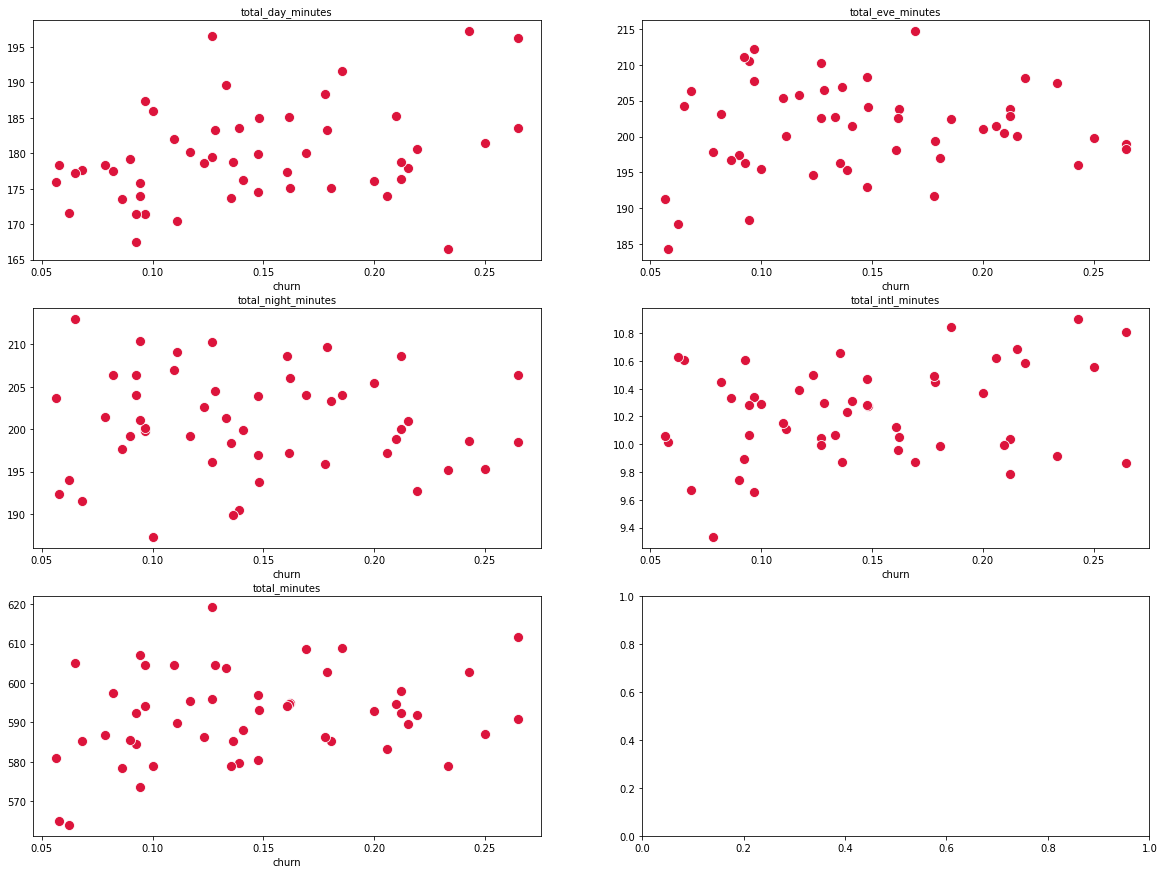

In [728]:
scatterplots(datos_estados, 'churn', minutos)

##### Restantes

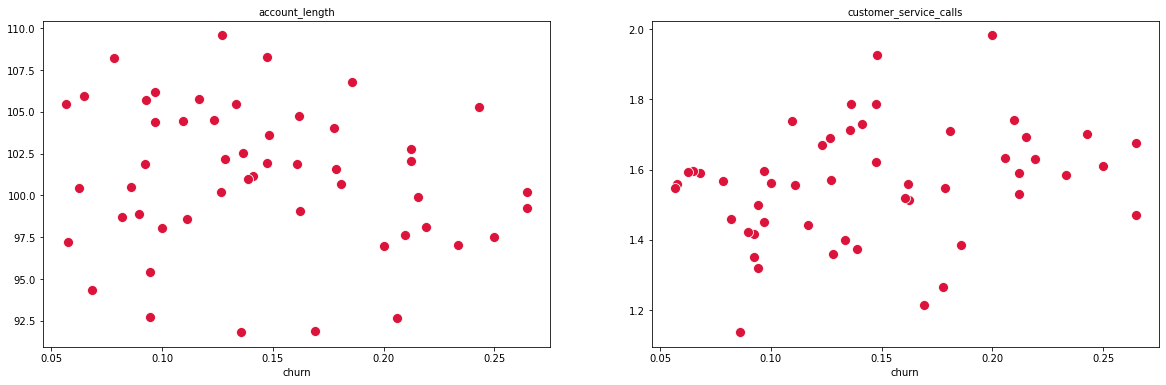

In [729]:
scatterplots(datos_estados, 'churn', restantes)

##### Planes

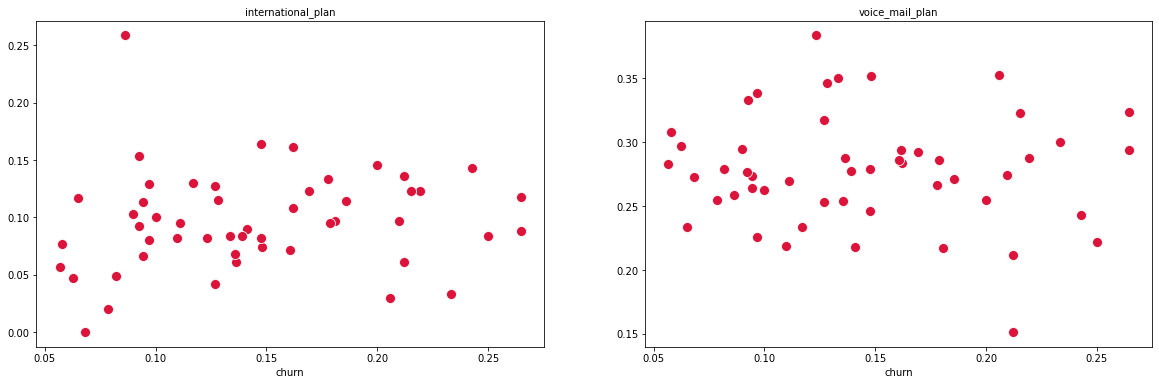

In [730]:
planes = [col for col in datos_estados.columns if 'plan' in col.lower()]
scatterplots(datos_estados, 'churn', planes)

##### Categóricas

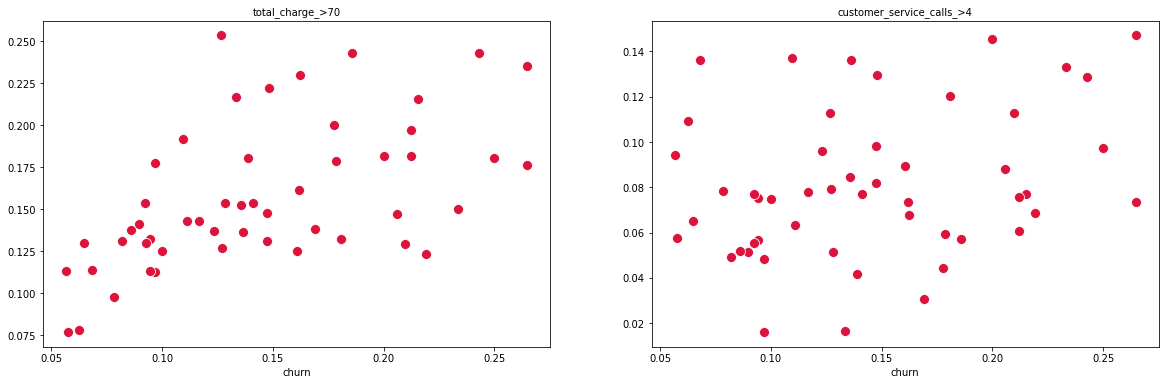

In [731]:
scatterplots(datos_estados, 'churn', columnas_interes)

### Churn

In [732]:
condiciones = [
    datos['state_risk']=='High',
    datos['state_risk']=='Low'
]
valores = [2,0]
datos['state_risk']=np.select(condiciones, valores, 1)

In [733]:
corr = datos.corr(numeric_only= True)
corr

,account_length,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,...,customer_service_calls,international_plan,voice_mail_plan,churn,total_calls,total_charge,total_minutes,total_charge_>70,customer_service_calls_>4,state_risk
account_length,1.000000,-0.011245,0.015601,0.040594,0.015597,0.003743,0.027983,0.003744,-0.015699,-0.008409,...,-0.003599,0.026816,-0.002595,0.003057,0.035663,0.013060,0.003281,-0.003106,0.011417,-0.018213
number_vmail_messages,-0.011245,1.000000,-0.007033,-0.003235,-0.007039,0.020023,-0.001936,0.020037,0.000515,0.012910,...,-0.007273,0.000843,0.956500,-0.089106,0.006111,0.002506,0.007560,0.010779,-0.001775,-0.002394
total_day_minutes,0.015601,-0.007033,1.000000,-0.025198,1.000000,-0.000110,0.006634,-0.000121,0.002638,0.035645,...,-0.006130,0.049677,-0.012028,0.216172,0.010321,0.881287,0.604621,0.581344,-0.007929,0.044345
total_day_calls,0.040594,-0.003235,-0.025198,1.000000,-0.025198,-0.020229,0.002724,-0.020231,0.014362,-0.025206,...,-0.032588,0.020944,-0.004175,0.008962,0.570280,-0.025264,-0.017742,-0.006812,-0.009650,-0.012701
total_day_charge,0.015597,-0.007039,1.000000,-0.025198,1.000000,-0.000104,0.006632,-0.000115,0.002637,0.035646,...,-0.006136,0.049673,-0.012033,0.216167,0.010320,0.881289,0.604624,0.581342,-0.007926,0.044346
total_eve_minutes,0.003743,0.020023,-0.000110,-0.020229,-0.000104,1.000000,-0.007036,1.000000,-0.001607,0.017844,...,-0.016044,0.020789,0.023825,0.084246,-0.004709,0.414821,0.568310,0.262848,-0.013184,0.027160
total_eve_calls,0.027983,-0.001936,0.006634,0.002724,0.006632,-0.007036,1.000000,-0.007024,0.002255,0.010530,...,0.009371,0.006247,-0.001349,0.014471,0.590222,0.003916,0.001471,-0.002076,0.023137,0.024344
total_eve_charge,0.003744,0.020037,-0.000121,-0.020231,-0.000115,1.000000,-0.007024,1.000000,-0.001610,0.017859,...,-0.016040,0.020794,0.023837,0.084243,-0.004694,0.414809,0.568301,0.262845,-0.013177,0.027157
total_night_minutes,-0.015699,0.000515,0.002638,0.014362,0.002637,-0.001607,0.002255,-0.001610,1.000000,0.010589,...,-0.007703,-0.023503,-0.002154,0.044650,0.014572,0.215887,0.557815,0.145699,-0.014049,-0.021305
total_night_calls,-0.008409,0.012910,0.035645,-0.025206,0.035646,0.017844,0.010530,0.017859,0.010589,1.000000,...,-0.015202,0.023371,0.024050,0.001670,0.559956,0.040680,0.037388,0.003213,-0.027664,0.036960


<Axes: >

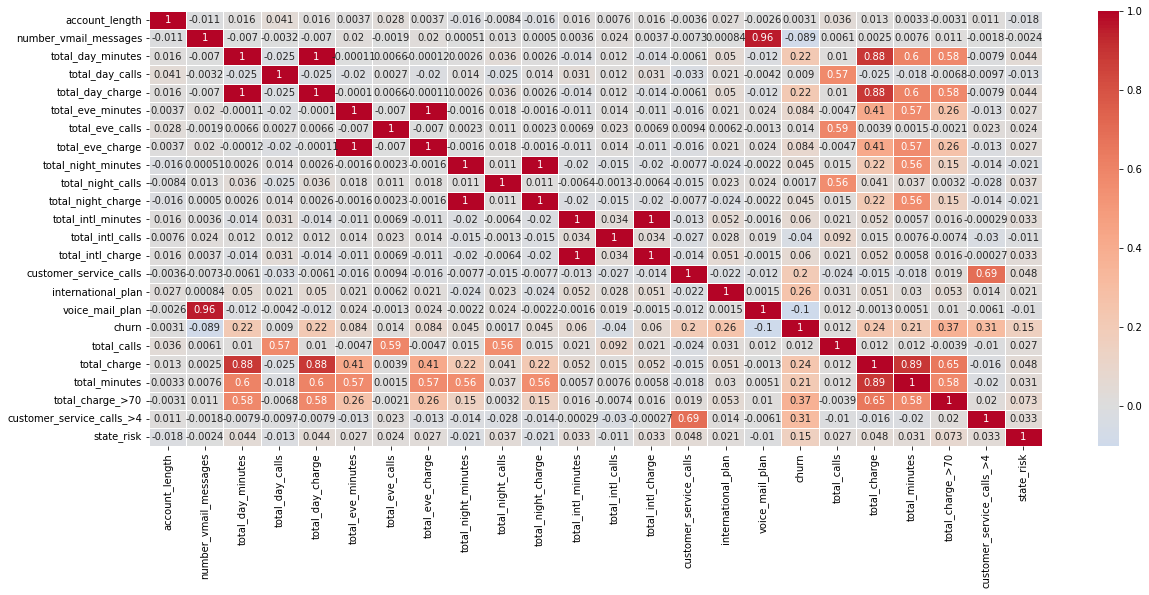

In [734]:
plt.figure(figsize = (20,8))
sns.heatmap(corr, cmap = "coolwarm", annot=True, center=0, linewidths=0.5)

In [735]:
tabla_de_contingencia_cargos = pd.crosstab(datos["churn"], datos["total_charge_>70"])
print(tabla_de_contingencia_cargos)
cramer_churn_area = stats.contingency.association(tabla_de_contingencia_cargos, method = "cramer")
print(f"V de Cramer Churn/Total charge >70: ",{cramer_churn_area})

tabla_de_contingencia_atencion = pd.crosstab(datos["churn"], datos["customer_service_calls_>4"])
print(tabla_de_contingencia_atencion)
cramer_churn_area = stats.contingency.association(tabla_de_contingencia_atencion, method = "cramer")
print(f"V de Cramer Churn/Customer service calls >4: ",{cramer_churn_area})

tabla_de_contingencia_internacional = pd.crosstab(datos["churn"], datos["international_plan"])
print(tabla_de_contingencia_internacional)
cramer_churn_internacional = stats.contingency.association(tabla_de_contingencia_internacional, method = "cramer")
print(f"V de Cramer Churn/Internacional: ",{cramer_churn_internacional})

tabla_de_contingencia_buzon = pd.crosstab(datos["churn"], datos["voice_mail_plan"])
print(tabla_de_contingencia_buzon)
cramer_churn_buzon = stats.contingency.association(tabla_de_contingencia_buzon, method = "cramer")
print(f"V de Cramer Churn/Buzon: ",{cramer_churn_buzon})

tabla_de_contingencia_area = pd.crosstab(datos["churn"], datos["area_code"])
print(tabla_de_contingencia_area)
cramer_churn_area = stats.contingency.association(tabla_de_contingencia_area, method = "cramer")
print(f"V de Cramer Churn/Area: ",{cramer_churn_area})

tabla_de_contingencia_riesgo = pd.crosstab(datos["churn"], datos["state_risk"])
print(tabla_de_contingencia_riesgo)
cramer_churn_riesgo = stats.contingency.association(tabla_de_contingencia_riesgo, method = "cramer")
print(f"V de Cramer Churn/Riesgo: ",{cramer_churn_riesgo})

cramer_churn_estados = stats.contingency.association(tabla_de_contingencia_estados, method = "cramer")
print(f"V de Cramer Churn/Estados: ",{cramer_churn_estados})

total_charge_>70  False  True 
churn                         
False              2059    221
True                203    183
V de Cramer Churn/Total charge >70:  {0.370129483162748}
customer_service_calls_>4  False  True 
churn                                  
False                       2174    106
True                         275    111
V de Cramer Churn/Customer service calls >4:  {0.3102318333596739}
international_plan  False  True 
churn                           
False                2132    148
True                  277    109
V de Cramer Churn/Internacional:  {0.2592852091253146}
voice_mail_plan  False  True 
churn                        
False             1585    695
True               319     67
V de Cramer Churn/Buzon:  {0.10222274767976945}
area_code  408   415  510
churn                    
False      579  1135  566
True        94   197   95
V de Cramer Churn/Area:  {0.009728200906374437}
state_risk    0     1    2
churn                     
False       557  1198  525
True

In [736]:
tabla_de_contingencia_cargos_riesgo = pd.crosstab(datos["state_risk"], datos["total_charge_>70"])
print(tabla_de_contingencia_cargos_riesgo)
cramer_churn_area = stats.contingency.association(tabla_de_contingencia_cargos_riesgo, method = "cramer")
print(f"V de Cramer State risk/Total charge >70: ",{cramer_churn_area})

tabla_de_contingencia_atencion_riesgo = pd.crosstab(datos["state_risk"], datos["customer_service_calls_>4"])
print(tabla_de_contingencia_atencion_riesgo)
cramer_churn_area = stats.contingency.association(tabla_de_contingencia_atencion_riesgo, method = "cramer")
print(f"V de Cramer State risk/Customer service calls >4: ",{cramer_churn_area})

tabla_de_contingencia_internacional_riesgo = pd.crosstab(datos["state_risk"], datos["international_plan"])
print(tabla_de_contingencia_internacional_riesgo)
cramer_churn_internacional = stats.contingency.association(tabla_de_contingencia_internacional_riesgo, method = "cramer")
print(f"V de Cramer State risk/Internacional: ",{cramer_churn_internacional})

tabla_de_contingencia_buzon_riesgo = pd.crosstab(datos["state_risk"], datos["voice_mail_plan"])
print(tabla_de_contingencia_buzon_riesgo)
cramer_churn_buzon = stats.contingency.association(tabla_de_contingencia_buzon_riesgo, method = "cramer")
print(f"V de Cramer State risk/Buzon: ",{cramer_churn_buzon})

tabla_de_contingencia_area_riesgo = pd.crosstab(datos["state_risk"], datos["area_code"])
print(tabla_de_contingencia_area_riesgo)
cramer_churn_area = stats.contingency.association(tabla_de_contingencia_area_riesgo, method = "cramer")
print(f"V de Cramer State risk/Area: ",{cramer_churn_area})

total_charge_>70  False  True 
state_risk                    
0                   532     68
1                  1179    208
2                   551    128
V de Cramer State risk/Total charge >70:  {0.07261529362774519}
customer_service_calls_>4  False  True 
state_risk                             
0                            555     45
1                           1283    104
2                            611     68
V de Cramer State risk/Customer service calls >4:  {0.04008831710269411}
international_plan  False  True 
state_risk                      
0                     549     51
1                    1251    136
2                     609     70
V de Cramer State risk/Internacional:  {0.021978952626074744}
voice_mail_plan  False  True 
state_risk                   
0                  430    170
1                  979    408
2                  495    184
V de Cramer State risk/Buzon:  {0.021415392255172454}
area_code   408  415  510
state_risk               
0           148  301  151

In [737]:
columnas_excluidas = minutos + llamadas + cargos + ['number_vmail_messages', 'customer_service_calls'] 
columnas_excluidas.remove('total_calls')
print(columnas_excluidas)
datos_limpios = datos.drop(columns = columnas_excluidas)    
datos_limpios

['total_day_minutes', 'total_eve_minutes', 'total_night_minutes', 'total_intl_minutes', 'total_minutes', 'total_day_calls', 'total_eve_calls', 'total_night_calls', 'total_intl_calls', 'total_day_charge', 'total_eve_charge', 'total_night_charge', 'total_intl_charge', 'total_charge', 'number_vmail_messages', 'customer_service_calls']


,state,account_length,area_code,international_plan,voice_mail_plan,churn,total_calls,total_charge_>70,customer_service_calls_>4,state_risk
id_customer,,,,,,,,,,
446,VA,121,415,False,False,False,357,False,False,0
2371,NM,93,415,False,False,False,291,True,False,1
3223,NC,72,415,False,False,False,338,False,False,1
2700,NJ,88,510,False,False,False,290,False,False,2
794,OK,96,415,False,False,False,252,True,True,1
...,...,...,...,...,...,...,...,...,...,...
2155,OK,46,415,False,False,False,389,False,False,1
1980,SD,138,510,False,False,False,286,False,False,1
240,NY,167,415,False,False,False,320,False,False,1


## Distribución

In [738]:
churn_true = datos_limpios[datos_limpios['churn']==True]
churn_false = datos_limpios[datos_limpios['churn']==False]

In [739]:
risk_0 = datos_limpios[datos_limpios['state_risk']==0]
risk_1 = datos_limpios[datos_limpios['state_risk']==1]
risk_2 = datos_limpios[datos_limpios['state_risk']==2]

### Funciones

In [740]:
def boxplot_churn(col): 
    """Boxplot coloreando x churn"""
    fig, axes = plt.subplots(nrows=1, ncols=len(col), figsize = (15,6))

    for i,col in enumerate(col):
        sns.boxplot(data = datos_limpios, x = 'churn', y=col, ax=axes[i], palette='Set2')
        axes[i].set_title(col, fontsize = 10)
        axes[i].set_ylabel('')
    plt.show()

In [741]:
def boxplot_risk(col): 
    """Histograma coloreando x riesgo de estado"""
    fig, axes = plt.subplots(nrows=1, ncols=len(col), figsize = (15,6))

    for i,col in enumerate(col):
        sns.boxplot(data = datos_limpios, x = 'state_risk', y=col, ax=axes[i], palette='Set1')
        axes[i].set_title(col, fontsize = 10)
        axes[i].set_ylabel('')
    plt.show()

In [742]:
def histogramas_risk(col):
    """Histograma coloreando x riesgo de estado"""
    columnas = len(col)
    fig, axes = plt.subplots(nrows=1, ncols=columnas, figsize = (20,4))

    for i,col in enumerate(col):
        sns.histplot(data=datos, x=col, hue="state_risk", multiple="layer", alpha=0.2, ax = axes[i], palette='Set2', kde = True)
        axes[i].set_title(col, fontsize = 10)
        axes[i].set_ylabel('')
    plt.tight_layout
    plt.show

In [743]:
def prueba_normalidad_churn(columnas, churn):
    for col in columnas:
        stat, p_value = stats.normaltest(churn[col])
        print('------------------------------------\n')
        print(f'-------------Churn', churn['churn'].iloc[0],'-------------\n')
        print('------------------------------------\n')
        print("----------- Prueba:",col,"-------------")
        print(f"Estadístico de la prueba: {stat:.4f}")
        print(f"p-value: {p_value}")
        alpha = 0.05
        if p_value > alpha:
            print("Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.")
        else:
            print("Interpretación: Se rechaza H0. Los datos NO siguen una distribución normal.")

In [744]:
def prueba_normalidad_risk(columnas, risk):
    for col in columnas:
        stat, p_value = stats.normaltest(risk[col])
        print('------------------------------------\n')
        print(f'-------------Risk', risk['state_risk'].iloc[0],'-------------\n')
        print('------------------------------------\n')
        print("----------- Prueba:",col,"-------------")
        print(f"Estadístico de la prueba: {stat:.4f}")
        print(f"p-value: {p_value}")
        alpha = 0.05
        if p_value > alpha:
            print("Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.")
        else:
            print("Interpretación: Se rechaza H0. Los datos NO siguen una distribución normal.")

### Churn

#### Graficos

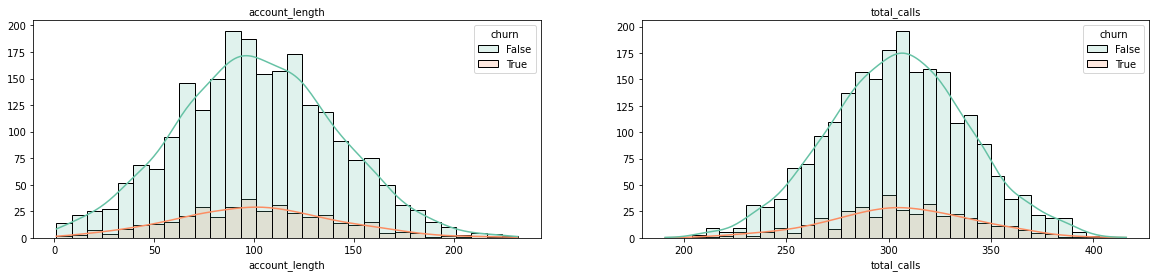

In [745]:
columnas_numericas = datos_limpios.select_dtypes(include='number').columns.tolist()
columnas_numericas.remove('state_risk')

histogramas(columnas_numericas)

C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\1519128065.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = datos_limpios, x = 'churn', y=col, ax=axes[i], palette='Set2')
C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\1519128065.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = datos_limpios, x = 'churn', y=col, ax=axes[i], palette='Set2')


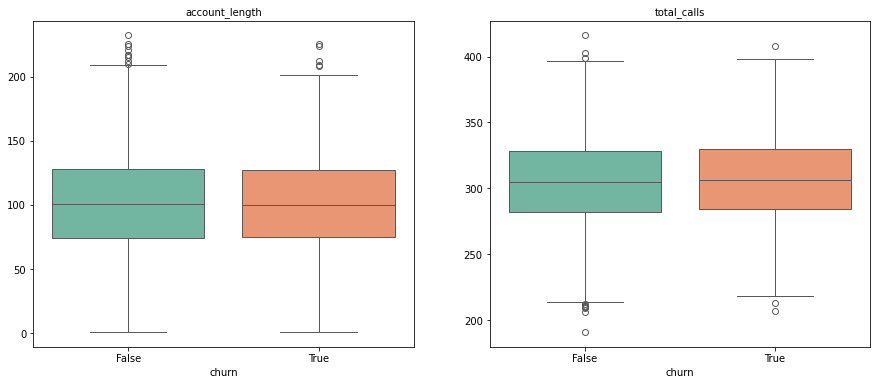

In [746]:
boxplot_churn(columnas_numericas)

#### Pruebas de hipótesis

In [747]:
prueba_normalidad_churn(columnas_numericas, churn_true)

------------------------------------

-------------Churn True -------------

------------------------------------

----------- Prueba: account_length -------------
Estadístico de la prueba: 2.3760
p-value: 0.30483138627218326
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.
------------------------------------

-------------Churn True -------------

------------------------------------

----------- Prueba: total_calls -------------
Estadístico de la prueba: 0.4508
p-value: 0.7982095070385897
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.


In [748]:
prueba_normalidad_churn(columnas_numericas, churn_false)

------------------------------------

-------------Churn False -------------

------------------------------------

----------- Prueba: account_length -------------
Estadístico de la prueba: 5.9820
p-value: 0.05023822624026207
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.
------------------------------------

-------------Churn False -------------

------------------------------------

----------- Prueba: total_calls -------------
Estadístico de la prueba: 0.9462
p-value: 0.623068672637688
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.


### Riesgo

#### Graficos

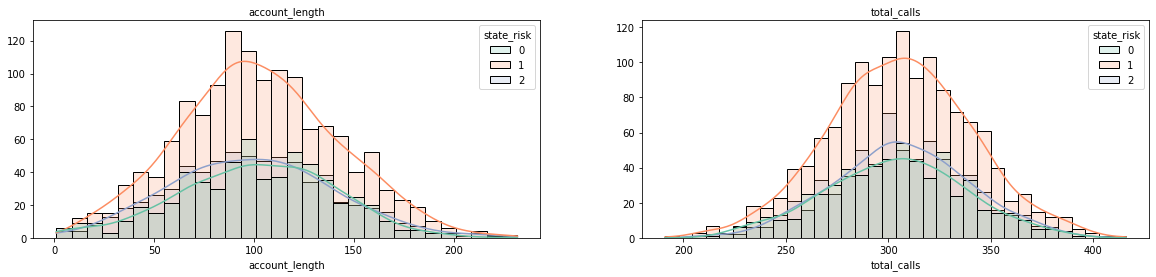

In [749]:
histogramas_risk(columnas_numericas)

C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\608510483.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = datos_limpios, x = 'state_risk', y=col, ax=axes[i], palette='Set1')
C:\Users\mois_\AppData\Local\Temp\ipykernel_19932\608510483.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = datos_limpios, x = 'state_risk', y=col, ax=axes[i], palette='Set1')


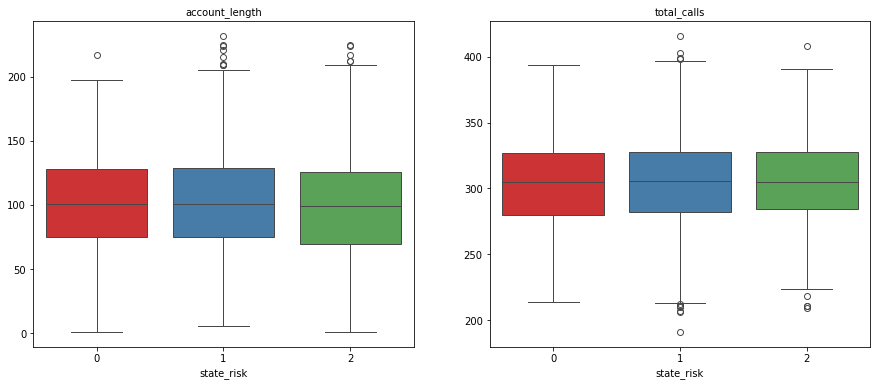

In [750]:
boxplot_risk(columnas_numericas)

#### Pruebas de hipótesis

In [751]:
prueba_normalidad_risk(columnas_numericas, risk_0)

------------------------------------

-------------Risk 0 -------------

------------------------------------

----------- Prueba: account_length -------------
Estadístico de la prueba: 3.5208
p-value: 0.17197962501381647
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.
------------------------------------

-------------Risk 0 -------------

------------------------------------

----------- Prueba: total_calls -------------
Estadístico de la prueba: 2.3041
p-value: 0.31598679668384294
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.


In [752]:
prueba_normalidad_risk(columnas_numericas, risk_1)

------------------------------------

-------------Risk 1 -------------

------------------------------------

----------- Prueba: account_length -------------
Estadístico de la prueba: 8.3537
p-value: 0.015346880943601085
Interpretación: Se rechaza H0. Los datos NO siguen una distribución normal.
------------------------------------

-------------Risk 1 -------------

------------------------------------

----------- Prueba: total_calls -------------
Estadístico de la prueba: 0.0500
p-value: 0.9753308018409901
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.


In [753]:
prueba_normalidad_risk(columnas_numericas, risk_2)

------------------------------------

-------------Risk 2 -------------

------------------------------------

----------- Prueba: account_length -------------
Estadístico de la prueba: 4.3871
p-value: 0.11152040207385809
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.
------------------------------------

-------------Risk 2 -------------

------------------------------------

----------- Prueba: total_calls -------------
Estadístico de la prueba: 0.2625
p-value: 0.8770165431856617
Interpretación: No se rechaza H0. Los datos SÍ siguen una distribución normal.


## Pruebas de hipótesis significancia

### Funciones

In [754]:
def prueba_medias(col, nombre:str, churn: bool, normal = True):
  if churn:
    grupo_1 = datos[datos['churn']==True][col]
    grupo_2 = datos[datos['churn']==False][col]
    if normal:
      stat_charge, p_value_charge = stats.ttest_ind(grupo_1, grupo_2, alternative = 'two-sided')
      prueba = "Prueba t de Student"
      estadistico = "t"
    else:
      stat_charge, p_value_charge = stats.mannwhitneyu(grupo_1, grupo_2, alternative='two-sided')
      prueba = "Prueba U de Man-Whitney"
      estadistico = "U"
  else:
    grupo_1 = datos[datos['state_risk']==0][col]
    grupo_2 = datos[datos['state_risk']==1][col]
    grupo_3 = datos[datos['state_risk']==2][col]
    if normal:
      stat_charge, p_value_charge = stats.f_oneway(grupo_1, grupo_2, grupo_3)
      prueba = "Prueba ANOVA"
      estadistico = "f"
    else:
      stat_charge, p_value_charge = stats.kruskal(grupo_1, grupo_2, grupo_3)
      prueba = "Prueba de Kruskal-Wallis"
      estadistico = "H"
  print(f"---------------{nombre}---------------")
  print(prueba)
  print(f"Estadístico {estadistico}: {stat_charge:.4f}")
  print(f"P-value: {p_value_charge}")

  if p_value_charge < 0.05:
    print(
        f"¡La diferencia ES estadísticamente significativa! ({nombre} influye"
        " en el churn)."
    )
  else:
    print(
        "No hay evidencia suficiente para decir que hay una diferencia real"
        " (podría ser por puro azar)."
    )

In [755]:
def prueba_tabla_contingencia(tabla_de_contingencia, nombre:str, nombre2:str):
    print(tabla_de_contingencia)
    chi2, p_value, dof, expected = stats.chi2_contingency(tabla_de_contingencia)

    print(f"Estadístico Chi2: {chi2:.4f}")
    print(f"Valor p (p-value): {p_value:.5f}")

    alpha = 0.05
    if p_value < alpha:
        print("\nResultado: Se rechaza la hipótesis nula.")
        print(f"Hay una relación significativa entre {nombre} y {nombre2} (las variables NO son independientes).")
    else:
        print("\nResultado: No se rechaza la hipótesis nula.")
        print("No hay evidencia de relación entre las variables (son independientes).")

### Para churn

#### Total de llamadas

In [756]:
prueba_medias("total_calls", "Llamadas totales", True, True)

---------------Llamadas totales---------------
Prueba t de Student
Estadístico t: 0.6032
P-value: 0.546417253185465
No hay evidencia suficiente para decir que hay una diferencia real (podría ser por puro azar).


#### Duración de cuenta

In [757]:
prueba_medias("account_length", "Duración de cuenta", True, False)

---------------Duración de cuenta---------------
Prueba U de Man-Whitney
Estadístico U: 440100.0000
P-value: 0.9966054064668398
No hay evidencia suficiente para decir que hay una diferencia real (podría ser por puro azar).


#### +70 Cargos

In [758]:
prueba_tabla_contingencia(tabla_de_contingencia_cargos, 'Churn', '+70 cargos')

total_charge_>70  False  True 
churn                         
False              2059    221
True                203    183
Estadístico Chi2: 362.3034
Valor p (p-value): 0.00000

Resultado: Se rechaza la hipótesis nula.
Hay una relación significativa entre Churn y +70 cargos (las variables NO son independientes).


#### +4 Llamadas a servicio a cliente

In [759]:
prueba_tabla_contingencia(tabla_de_contingencia_atencion, 'Churn', '+4 llamadas a atención a cliente')

customer_service_calls_>4  False  True 
churn                                  
False                       2174    106
True                         275    111
Estadístico Chi2: 253.3719
Valor p (p-value): 0.00000

Resultado: Se rechaza la hipótesis nula.
Hay una relación significativa entre Churn y +4 llamadas a atención a cliente (las variables NO son independientes).


#### Plan internacional

In [760]:
prueba_tabla_contingencia(tabla_de_contingencia_internacional, 'Churn', 'Plan internacional')

international_plan  False  True 
churn                           
False                2132    148
True                  277    109
Estadístico Chi2: 176.7441
Valor p (p-value): 0.00000

Resultado: Se rechaza la hipótesis nula.
Hay una relación significativa entre Churn y Plan internacional (las variables NO son independientes).


#### Plan Buzón de voz

In [761]:
prueba_tabla_contingencia(tabla_de_contingencia_buzon, 'Churn', 'Plan de buzón de voz')

voice_mail_plan  False  True 
churn                        
False             1585    695
True               319     67
Estadístico Chi2: 27.2191
Valor p (p-value): 0.00000

Resultado: Se rechaza la hipótesis nula.
Hay una relación significativa entre Churn y Plan de buzón de voz (las variables NO son independientes).


#### Código de área

In [762]:
prueba_tabla_contingencia(tabla_de_contingencia_area, 'Churn', 'Código de área')

area_code  408   415  510
churn                    
False      579  1135  566
True        94   197   95
Estadístico Chi2: 0.2523
Valor p (p-value): 0.88148

Resultado: No se rechaza la hipótesis nula.
No hay evidencia de relación entre las variables (son independientes).


#### Riesgo Estados

In [763]:
prueba_tabla_contingencia(tabla_de_contingencia_riesgo, 'Churn', 'Riesgo de estado')

state_risk    0     1    2
churn                     
False       557  1198  525
True         43   189  154
Estadístico Chi2: 63.6083
Valor p (p-value): 0.00000

Resultado: Se rechaza la hipótesis nula.
Hay una relación significativa entre Churn y Riesgo de estado (las variables NO son independientes).


### Para el estado y riesgo de los estados

#### Total llamadas

In [764]:
correlacion, p_valor = stats.pearsonr(x=datos_estados['total_calls'], y = datos_estados['churn'])
r2 = correlacion ** 2
n_estados = len(datos_estados) 

print(f"Número de estados (n): {n_estados}")
print(f"R^2 (Varianza explicada a nivel estatal): {r2:.4f}")
print(f"P-valor (a nivel estatal): {p_valor}")

if p_valor < 0.05:
    print("Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.")
else:
    print("Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).")

Número de estados (n): 51
R^2 (Varianza explicada a nivel estatal): 0.0047
P-valor (a nivel estatal): 0.634184804381043
Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).


In [765]:
prueba_medias("total_calls", "Llamadas totales", False, True)

---------------Llamadas totales---------------
Prueba ANOVA
Estadístico f: 1.1451
P-value: 0.3183350469415571
No hay evidencia suficiente para decir que hay una diferencia real (podría ser por puro azar).


#### Duración de cuenta

In [766]:
correlacion, p_valor = stats.pearsonr(x=datos_estados['account_length'], y = datos_estados['churn'])
r2 = correlacion ** 2
n_estados = len(datos_estados) 

print(f"Número de estados (n): {n_estados}")
print(f"R^2 (Varianza explicada a nivel estatal): {r2:.4f}")
print(f"P-valor (a nivel estatal): {p_valor}")

if p_valor < 0.05:
    print("Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.")
else:
    print("Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).")

Número de estados (n): 51
R^2 (Varianza explicada a nivel estatal): 0.0211
P-valor (a nivel estatal): 0.30941278016217294
Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).


In [767]:
prueba_medias("account_length", "Duración de cuenta", False, False)

---------------Duración de cuenta---------------
Prueba de Kruskal-Wallis
Estadístico H: 3.2935
P-value: 0.19267494394827267
No hay evidencia suficiente para decir que hay una diferencia real (podría ser por puro azar).


#### +70 cargos

In [768]:
correlacion, p_valor = stats.pearsonr(x=datos_estados['total_charge_>70'], y = datos_estados['churn'])
r2 = correlacion ** 2
n_estados = len(datos_estados) 

print(f"Número de estados (n): {n_estados}")
print(f"R^2 (Varianza explicada a nivel estatal): {r2:.4f}")
print(f"P-valor (a nivel estatal): {p_valor}")

if p_valor < 0.05:
    print("Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.")
else:
    print("Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).")

Número de estados (n): 51
R^2 (Varianza explicada a nivel estatal): 0.3142
P-valor (a nivel estatal): 1.8880135524652683e-05
Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.


In [769]:
prueba_tabla_contingencia(tabla_de_contingencia_cargos_riesgo, 'Riesgo Estado', '+70 cargos')

total_charge_>70  False  True 
state_risk                    
0                   532     68
1                  1179    208
2                   551    128
Estadístico Chi2: 14.0578
Valor p (p-value): 0.00089

Resultado: Se rechaza la hipótesis nula.
Hay una relación significativa entre Riesgo Estado y +70 cargos (las variables NO son independientes).


#### +4 llamadas a servicio a cliente

In [770]:
correlacion, p_valor = stats.pearsonr(x=datos_estados['customer_service_calls_>4'], y = datos_estados['churn'])
r2 = correlacion ** 2
n_estados = len(datos_estados) 

print(f"Número de estados (n): {n_estados}")
print(f"R^2 (Varianza explicada a nivel estatal): {r2:.4f}")
print(f"P-valor (a nivel estatal): {p_valor}")

if p_valor < 0.05:
    print("Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.")
else:
    print("Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).")

Número de estados (n): 51
R^2 (Varianza explicada a nivel estatal): 0.0782
P-valor (a nivel estatal): 0.04693671272455492
Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.


In [771]:
prueba_tabla_contingencia(tabla_de_contingencia_atencion_riesgo, 'Riesgo Estado', '+4 llamadas a servicio a cliente')

customer_service_calls_>4  False  True 
state_risk                             
0                            555     45
1                           1283    104
2                            611     68
Estadístico Chi2: 4.2845
Valor p (p-value): 0.11739

Resultado: No se rechaza la hipótesis nula.
No hay evidencia de relación entre las variables (son independientes).


#### Plan internacional

In [772]:
correlacion, p_valor = stats.pearsonr(x=datos_estados['international_plan'], y = datos_estados['churn'])
r2 = correlacion ** 2
n_estados = len(datos_estados) 

print(f"Número de estados (n): {n_estados}")
print(f"R^2 (Varianza explicada a nivel estatal): {r2:.4f}")
print(f"P-valor (a nivel estatal): {p_valor}")

if p_valor < 0.05:
    print("Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.")
else:
    print("Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).")

Número de estados (n): 51
R^2 (Varianza explicada a nivel estatal): 0.0176
P-valor (a nivel estatal): 0.3534190892931552
Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).


In [773]:
prueba_tabla_contingencia(tabla_de_contingencia_internacional_riesgo, 'Riesgo Estado', 'Plan internacional')

international_plan  False  True 
state_risk                      
0                     549     51
1                    1251    136
2                     609     70
Estadístico Chi2: 1.2879
Valor p (p-value): 0.52522

Resultado: No se rechaza la hipótesis nula.
No hay evidencia de relación entre las variables (son independientes).


#### Plan Buzón de voz

In [774]:
correlacion, p_valor = stats.pearsonr(x=datos_estados['voice_mail_plan'], y = datos_estados['churn'])
r2 = correlacion ** 2
n_estados = len(datos_estados) 

print(f"Número de estados (n): {n_estados}")
print(f"R^2 (Varianza explicada a nivel estatal): {r2:.4f}")
print(f"P-valor (a nivel estatal): {p_valor}")

if p_valor < 0.05:
    print("Resultado: La variable SÍ es estadísticamente significativa para explicar la tasa entre estados.")
else:
    print("Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).")

Número de estados (n): 51
R^2 (Varianza explicada a nivel estatal): 0.0048
P-valor (a nivel estatal): 0.6279874042655144
Resultado: Con tan pocos estados, el R^2 no alcanza significancia estadística (podría ser azar).


In [775]:
prueba_tabla_contingencia(tabla_de_contingencia_buzon_riesgo, 'Riesgo Estado', 'Plan de buzón de voz')

voice_mail_plan  False  True 
state_risk                   
0                  430    170
1                  979    408
2                  495    184
Estadístico Chi2: 1.2227
Valor p (p-value): 0.54262

Resultado: No se rechaza la hipótesis nula.
No hay evidencia de relación entre las variables (son independientes).


#### Código de área

In [776]:
prueba_tabla_contingencia(tabla_de_contingencia_area_riesgo, 'Riesgo Estado', 'Código de área')

area_code   408  415  510
state_risk               
0           148  301  151
1           356  687  344
2           169  344  166
Estadístico Chi2: 0.4010
Valor p (p-value): 0.98239

Resultado: No se rechaza la hipótesis nula.
No hay evidencia de relación entre las variables (son independientes).
